# 23CSE351 – Foundations of Data Science
## Case Study: Hotel Booking Demand – Understanding and Predicting Booking Cancellations

**Name:** [Your Name]  |  **Register No.:** [Your Register Number]  |  **Department:** [Your Department]

---
**Contents**
1. Problem statement and objectives
2. Dataset description
3. Data preprocessing (cleaning, transformation, reduction)
4. Exploratory data analysis (EDA)
5. Analysis questions (15) with visualisation
6. Hypothesis testing and A/B testing
7. Machine-learning model (classification)
8. Tableau dashboard (data export)
9. Conclusions, insights, limitations, future work, references

## 1. Problem Statement and Objectives

A resort hotel loses revenue whenever a booking is cancelled, because the room may remain empty or be resold at a lower price. In this dataset **about one in two bookings is cancelled**, so understanding *who cancels and why* is a direct business question.

**Objectives**
1. Clean and prepare the booking records for analysis.
2. Explore booking patterns: seasonality, lead time, stay length, price (ADR), guests and channels.
3. Answer 15 focused analysis questions, each with a suitable statistical concept, a visualisation and an interpretation.
4. Test the main findings with formal hypothesis tests (including A/B-style comparisons) so that decisions rest on evidence.
5. Build and evaluate one machine-learning model (logistic regression) that predicts cancellation, and explain *why* it is suitable.
6. Present the results in a Tableau dashboard and draw business conclusions.

> The statistical analysis is the core of this project. The ML model is one supporting step that turns the findings into a prediction tool.

## 2. Dataset Description

| Item | Detail |
|---|---|
| Name | Hotel Booking Demand dataset (Resort Hotel records) |
| Source | Antonio, de Almeida & Nunes (2019), *Hotel booking demand datasets*, **Data in Brief 22**, 41-49; also on Kaggle as "Hotel Booking Demand". Real booking data from a hotel property management system in Portugal. |
| File used | `hotel_bookings.csv` (the same file used in Review 1) |
| Size | 7,324 rows x 32 columns (rows after cleaning are reported below; the requirement is at least 500) |
| Period | Arrivals from July 2015 to early August 2016 |
| Target variable | `is_canceled` (1 = cancelled, 0 = not cancelled) |

**Main attributes:** `lead_time` (days between booking and arrival), `arrival_date_*`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`/`children`/`babies`, `meal`, `country`, `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`, `adr` (average daily rate), `booking_changes`, `total_of_special_requests`, `required_car_parking_spaces`, `previous_cancellations`, `reservation_status`.

**Important note on the file.** The CSV supplied is a partial extract: it contains only Resort Hotel rows and its final record is cut off. This is handled in preprocessing and discussed under limitations.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

RANDOM_STATE = 42
BLUE, RED, ORANGE, GREY = "#2e86ab", "#d1495b", "#edae49", "#8d99ae"
MONTHS = ["January","February","March","April","May","June","July","August",
          "September","October","November","December"]

## 3. Data Preprocessing

### 3.1 Loading and first look

In [2]:
raw = pd.read_csv("hotel_bookings.csv")
print("Shape of the raw file:", raw.shape)
display(raw.head())

Shape of the raw file: (7324, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27.000,1.000,0.000,0.000,2.000,0.000,0.000,BB,PRT,Direct,Direct,0.000,0.000,0.000,C,C,3.000,No Deposit,NaN,NaN,0.000,Transient,0.000,0.000,0.000,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27.000,1.000,0.000,0.000,2.000,0.000,0.000,BB,PRT,Direct,Direct,0.000,0.000,0.000,C,C,4.000,No Deposit,NaN,NaN,0.000,Transient,0.000,0.000,0.000,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27.000,1.000,0.000,1.000,1.000,0.000,0.000,BB,GBR,Direct,Direct,0.000,0.000,0.000,A,C,0.000,No Deposit,NaN,NaN,0.000,Transient,75.000,0.000,0.000,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27.000,1.000,0.000,1.000,1.000,0.000,0.000,BB,GBR,Corporate,Corporate,0.000,0.000,0.000,A,A,0.000,No Deposit,304.000,NaN,0.000,Transient,75.000,0.000,0.000,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27.000,1.000,0.000,2.000,2.000,0.000,0.000,BB,GBR,Online TA,TA/TO,0.000,0.000,0.000,A,A,0.000,No Deposit,240.000,NaN,0.000,Transient,98.000,0.000,1.000,Check-Out,2015-07-03


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7324 entries, 0 to 7323
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           7324 non-null   str    
 1   is_canceled                     7324 non-null   int64  
 2   lead_time                       7324 non-null   int64  
 3   arrival_date_year               7324 non-null   int64  
 4   arrival_date_month              7324 non-null   str    
 5   arrival_date_week_number        7323 non-null   float64
 6   arrival_date_day_of_month       7323 non-null   float64
 7   stays_in_weekend_nights         7323 non-null   float64
 8   stays_in_week_nights            7323 non-null   float64
 9   adults                          7323 non-null   float64
 10  children                        7323 non-null   float64
 11  babies                          7323 non-null   float64
 12  meal                            7323 non-null

In [4]:
# Data-quality audit: types, missing values and cardinality of every column
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(),
})
display(audit[audit["missing"] > 0])
print("Completely duplicated rows:", raw.duplicated().sum())
print("Month labels present      :", sorted(raw["arrival_date_month"].dropna().unique()))
print("Hotels present            :", raw["hotel"].dropna().unique())
print("Last record of the file (note the missing values):")
display(raw.tail(1).T.head(12))

Completely duplicated rows: 1836
Month labels present      : ['April', 'Aug', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
Hotels present            : <StringArray>
['Resort Hotel']
Length: 1, dtype: str
Last record of the file (note the missing values):


,dtype,missing,missing_%,unique_values
arrival_date_week_number,float64,1,0.010,53
arrival_date_day_of_month,float64,1,0.010,31
stays_in_weekend_nights,float64,1,0.010,12
stays_in_week_nights,float64,1,0.010,23
adults,float64,1,0.010,14
children,float64,1,0.010,5
babies,float64,1,0.010,3
meal,str,1,0.010,5
country,str,4,0.050,64
market_segment,str,1,0.010,6


,7323
hotel,Resort Hotel
is_canceled,1
lead_time,208
arrival_date_year,2016
arrival_date_month,Aug
arrival_date_week_number,NaN
arrival_date_day_of_month,NaN
stays_in_weekend_nights,NaN
stays_in_week_nights,NaN
adults,NaN


**What the audit shows**
- The file has **7,324 rows x 32 columns** and contains only the *Resort Hotel*. The last record (row 7,323) is **truncated**: every booking detail is missing, which explains the single missing value in most columns and the stray label `Aug` (it appears only in that record).
- `company` is missing for **94.5%** of rows and `agent` for **15.8%**. In the original data a missing agent means "no travel agent was involved", so it is coded 0 rather than imputed.
- **1,836 rows (25%) are exact duplicates**. They are removed so that identical bookings are not counted twice and, later, do not appear in both the training and the test sets.
- Several columns are stored as decimals although they are counts (adults, nights...), and are converted to integers.

### 3.2 Cleaning

In [5]:
df = raw.copy()
log = []   # (step, rows affected)

# 1) Remove the truncated final record (all booking details missing)
before = len(df)
df = df.dropna(subset=["adults", "market_segment", "hotel"])
log.append(("Remove incomplete / truncated record", before - len(df)))

# 2) Correct data types (counts stored as floats -> integers)
int_cols = ["arrival_date_week_number", "arrival_date_day_of_month", "stays_in_weekend_nights",
            "stays_in_week_nights", "adults", "children", "babies", "is_repeated_guest",
            "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]
df[int_cols] = df[int_cols].astype(int)

# 3) Missing values
#    company: ~94% missing -> column dropped later (reduction)
#    agent  : missing means "no travel agent"  -> coded 0
#    country: only a few missing                  -> "Unknown"
log.append(("Missing 'agent' coded as 0 (= no agent)", int(df["agent"].isna().sum())))
df["agent"] = df["agent"].fillna(0).astype(int)
log.append(("Missing 'country' set to 'Unknown'", int(df["country"].isna().sum())))
df["country"] = df["country"].fillna("Unknown")

# 4) Duplicate bookings
n_dup = df.duplicated().sum()
df = df.drop_duplicates()
log.append(("Remove duplicate rows", int(n_dup)))

# 5) Invalid records: bookings with zero guests
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
n_zero = (df["total_guests"] == 0).sum()
df = df[df["total_guests"] > 0]
log.append(("Remove bookings with 0 guests", int(n_zero)))

df = df.reset_index(drop=True)
display(pd.DataFrame(log, columns=["Cleaning step", "Rows / values affected"]))
print("Rows remaining:", len(df))

Rows remaining: 5481


,Cleaning step,Rows / values affected
0,Remove incomplete / truncated record,1
1,Missing 'agent' coded as 0 (= no agent),1156
2,Missing 'country' set to 'Unknown',3
3,Remove duplicate rows,1836
4,Remove bookings with 0 guests,6


### 3.3 Outlier treatment (ADR)

Q1=56.00, Q3=130.33, IQR=74.33 -> acceptable range [0.00, 241.83]
ADR values above the upper fence: 60 (1.1%)
Bookings with ADR = 0 (complimentary / free stays): 133


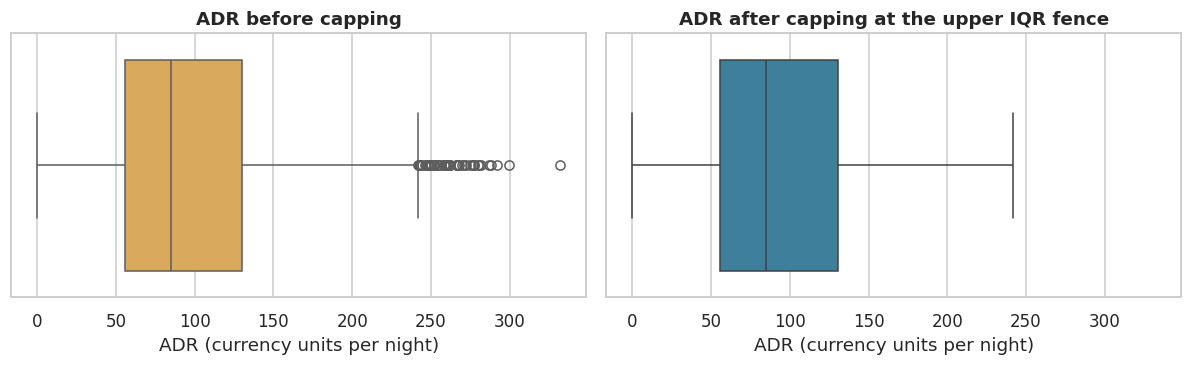

In [6]:
# ADR = Average Daily Rate (price per night). Inspect with the IQR rule.
Q1, Q3 = df["adr"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((df["adr"] < lower) | (df["adr"] > upper)).sum()
print(f"Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f} -> acceptable range [{max(lower,0):.2f}, {upper:.2f}]")
print("ADR values above the upper fence:", n_out, f"({n_out/len(df):.1%})")
print("Bookings with ADR = 0 (complimentary / free stays):", (df['adr'] == 0).sum())

df["adr_raw"] = df["adr"]                 # keep the original for reference
df["adr"] = df["adr"].clip(upper=upper)   # winsorise: cap, do not delete the bookings

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
sns.boxplot(x=df["adr_raw"], ax=axes[0], color=ORANGE)
axes[0].set_title("ADR before capping"); axes[0].set_xlabel("ADR (currency units per night)")
sns.boxplot(x=df["adr"], ax=axes[1], color=BLUE)
axes[1].set_title("ADR after capping at the upper IQR fence"); axes[1].set_xlabel("ADR (currency units per night)")
plt.tight_layout(); plt.show()

**Interpretation:** ADR is right-skewed. Only **60 bookings (1.1%)** lie above the upper IQR fence of about 242, so they are **capped, not deleted**; this keeps every booking and its cancellation outcome while stopping a few extreme prices from distorting means and the regression. There are also **133 bookings with ADR = 0** (free or complimentary stays, mostly from the Online TA and Groups segments). They are real records, so they are kept, but price questions (Q7, Q9, Q14, Q15, H6-H8) use **paid bookings only (ADR > 0)** because a free stay says nothing about pricing.

### 3.4 Transformation (feature engineering)

In [7]:
month_no = {m_: i for i, m_ in enumerate(MONTHS, 1)}
df["month_no"] = df["arrival_date_month"].map(month_no)
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"], month=df["month_no"],
                                         day=df["arrival_date_day_of_month"]))
df["arrival_date_month"] = pd.Categorical(df["arrival_date_month"], categories=MONTHS, ordered=True)
df["arrival_ym"] = df["arrival_date"].dt.to_period("M").astype(str)

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["has_children"] = ((df["children"] + df["babies"]) > 0).astype(int)
df["has_request"]  = (df["total_of_special_requests"] > 0).astype(int)
df["season"] = df["month_no"].map({12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
                                   6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"})
df["lead_group"] = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 10_000],
                          labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "180+ days"])
df["stay_group"] = pd.cut(df["total_nights"], bins=[-1, 0, 3, 7, 14, 10_000],
                          labels=["0 nights", "1-3 nights", "4-7 nights", "8-14 nights", "15+ nights"])
df["country_grp"] = np.where(df["country"] == "PRT", "Portugal", "International")
df["cancel_label"] = df["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})
df["revenue_at_stake"] = df["adr"] * df["total_nights"]      # estimated room revenue of the booking

display(df[["total_nights", "total_guests", "has_children", "has_request", "season",
            "lead_group", "stay_group", "country_grp", "revenue_at_stake"]].head())

,total_nights,total_guests,has_children,has_request,season,lead_group,stay_group,country_grp,revenue_at_stake
0,0,2,0,0,Summer,180+ days,0 nights,Portugal,0.000
1,0,2,0,0,Summer,180+ days,0 nights,Portugal,0.000
2,1,1,0,0,Summer,0-7 days,1-3 nights,International,75.000
3,1,1,0,0,Summer,8-30 days,1-3 nights,International,75.000
4,2,2,0,1,Summer,8-30 days,1-3 nights,International,196.000


### 3.5 Reduction (dropping columns that carry no usable information)

In [8]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Constant columns (no information):", constant_cols)

drop_cols = list(dict.fromkeys(constant_cols + [
    "company",                  # ~94% missing
    "reservation_status",       # LEAKAGE: it directly states whether the booking was cancelled
    "reservation_status_date",  # LEAKAGE: date of the cancellation / check-out event
    "assigned_room_type",       # decided after booking, not known when the booking is made
    "arrival_date_week_number", "arrival_date_day_of_month",   # redundant with arrival_date
]))
df = df.drop(columns=drop_cols)
print("Dropped:", drop_cols)

summary = pd.DataFrame({
    "Raw file": [raw.shape[0], raw.shape[1]],
    "Clean dataset": [df.shape[0], df.shape[1]],
}, index=["Rows", "Columns"])
display(summary)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Overall cancellation rate:", f"{df['is_canceled'].mean():.1%}")
OVERALL = df["is_canceled"].mean()

Constant columns (no information): ['hotel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled']
Dropped: ['hotel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'company', 'reservation_status', 'reservation_status_date', 'assigned_room_type', 'arrival_date_week_number', 'arrival_date_day_of_month']
Remaining missing values: 0
Overall cancellation rate: 49.9%


,Raw file,Clean dataset
Rows,7324,5481
Columns,32,36


**Result of preprocessing**
| Step | Action | Effect |
|---|---|---|
| Cleaning | removed 1 truncated record, 1,836 duplicates and 6 zero-guest bookings; coded missing agent/country | 7,324 -> **5,481 rows** (25% removed) |
| Transformation | added `total_nights`, `total_guests`, `has_children`, `has_request`, `season`, `lead_group`, `stay_group`, `country_grp`, `arrival_date`, `revenue_at_stake` | richer variables for analysis |
| Outlier handling | ADR capped at the IQR fence | extreme prices no longer dominate |
| Reduction | dropped `company` (94% missing), four constant columns (`hotel`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`), leakage columns (`reservation_status`, `reservation_status_date`) and others | **no missing values remain** |

The constant columns tell us something about this extract: it contains **no repeat guests and no guests with a cancellation history**, so those well-known predictors cannot be studied here.

## 4. Exploratory Data Analysis (EDA)

In [9]:
num_cols = ["lead_time", "total_nights", "total_guests", "adr", "booking_changes",
            "total_of_special_requests", "required_car_parking_spaces", "days_in_waiting_list"]
desc = df[num_cols].describe().T
desc["skewness"] = df[num_cols].skew()
display(desc)

,count,mean,std,min,25%,50%,75%,max,skewness
lead_time,"5,481.000",90.435,80.921,0.000,28.000,68.000,135.000,737.000,1.240
total_nights,"5,481.000",4.959,3.466,0.000,2.000,4.000,7.000,46.000,2.164
total_guests,"5,481.000",2.162,1.598,1.000,2.000,2.000,2.000,55.000,18.956
adr,"5,481.000",96.980,53.520,0.000,56.000,85.000,130.330,241.825,0.678
booking_changes,"5,481.000",0.256,0.670,0.000,0.000,0.000,0.000,17.000,5.600
total_of_special_requests,"5,481.000",0.656,0.828,0.000,0.000,0.000,1.000,4.000,1.055
required_car_parking_spaces,"5,481.000",0.094,0.294,0.000,0.000,0.000,0.000,2.000,2.841
days_in_waiting_list,"5,481.000",0.545,7.637,0.000,0.000,0.000,0.000,122.000,14.692


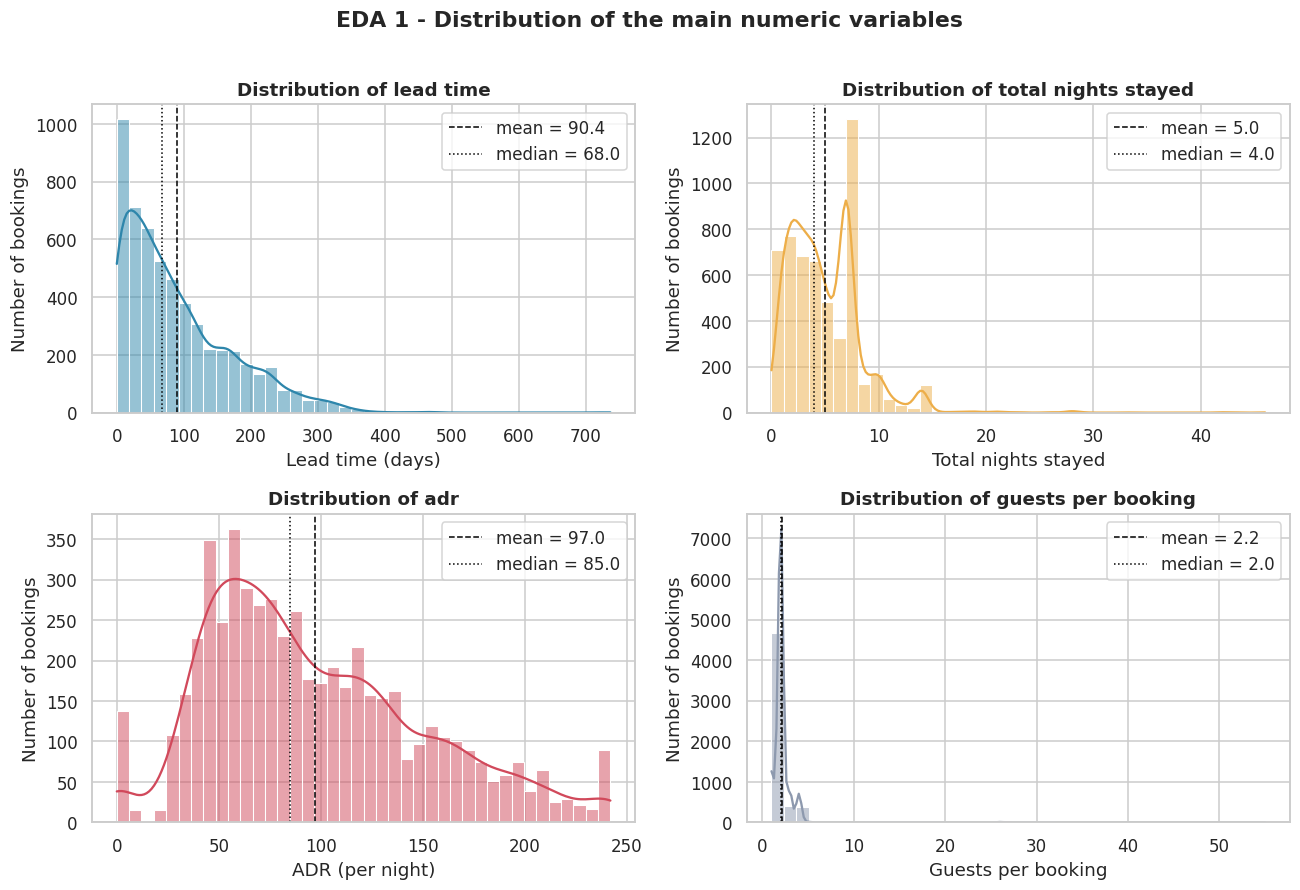

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, color, xl in zip(axes.ravel(), ["lead_time", "total_nights", "adr", "total_guests"],
                              [BLUE, ORANGE, RED, GREY],
                              ["Lead time (days)", "Total nights stayed", "ADR (per night)", "Guests per booking"]):
    sns.histplot(df[col], bins=40, kde=True, color=color, ax=ax)
    ax.axvline(df[col].mean(), color="black", ls="--", lw=1, label=f"mean = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="black", ls=":", lw=1, label=f"median = {df[col].median():.1f}")
    ax.set_title(f"Distribution of {xl.split(' (')[0].lower()}"); ax.set_xlabel(xl); ax.set_ylabel("Number of bookings"); ax.legend()
plt.suptitle("EDA 1 - Distribution of the main numeric variables", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

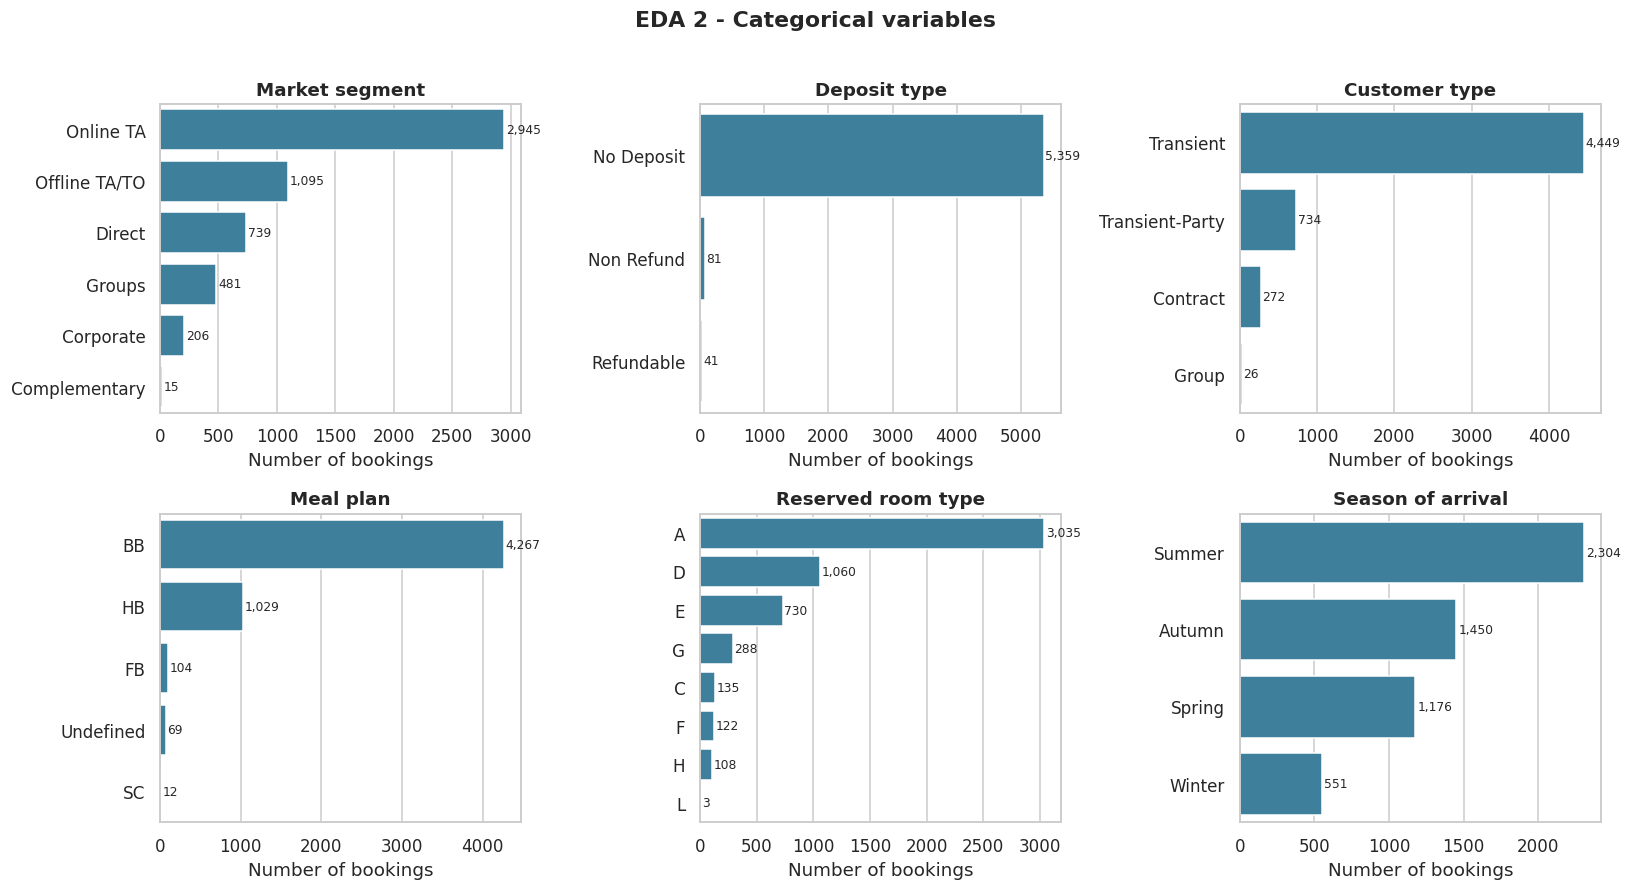

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col, title in zip(axes.ravel(),
        ["market_segment", "deposit_type", "customer_type", "meal", "reserved_room_type", "season"],
        ["Market segment", "Deposit type", "Customer type", "Meal plan", "Reserved room type", "Season of arrival"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, color=BLUE, ax=ax)
    for p in ax.patches:
        ax.text(p.get_width() + 15, p.get_y() + p.get_height() / 2, f"{int(p.get_width()):,}", va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel("Number of bookings"); ax.set_ylabel("")
plt.suptitle("EDA 2 - Categorical variables", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

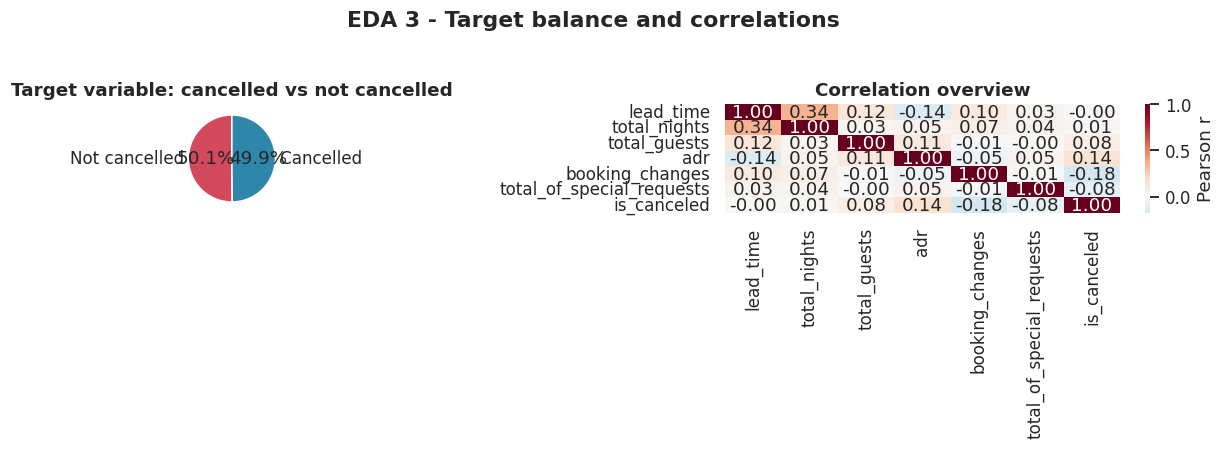

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df["cancel_label"].value_counts()
axes[0].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=[RED, BLUE], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[0].set_title("Target variable: cancelled vs not cancelled")
sns.heatmap(df[["lead_time", "total_nights", "total_guests", "adr", "booking_changes",
                "total_of_special_requests", "is_canceled"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, ax=axes[1], cbar_kws={"label": "Pearson r"})
axes[1].set_title("Correlation overview")
plt.suptitle("EDA 3 - Target balance and correlations", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

### What we learned from the EDA
1. **Target balance:** 2,734 of 5,481 bookings (**49.9%**) are cancelled, so the classes are balanced and accuracy is a meaningful metric.
2. **Skewed numeric variables:** lead time (skew 1.24), nights (2.16) and especially guests per booking (skew 19, a few group bookings of up to 55 people) are right-skewed, so the median describes a "typical" booking better than the mean, and extreme values must be capped before modelling.
3. **Channel mix:** Online travel agents (Online TA) supply **54%** of bookings, offline agents 20% and direct bookings 14%. **98%** of bookings carry no deposit.
4. **Guest mix:** **60%** of bookings are from Portugal; 81% are "Transient" individual travellers; 78% take bed-and-breakfast.
5. **Weak correlations everywhere:** no numeric variable has a strong linear link with cancellation (the biggest is parking requests, r about -0.3), which tells us cancellation is driven mainly by *categorical* factors (channel, country, deposit) and not by a single numeric variable.
6. **Two data-quality warnings that shape the rest of the work:** the data cover only **July 2015 - early August 2016**, and the cancellation rate is very different between the two years (Q2). Both are examined below instead of being ignored.

## 5. Analysis Questions

Each question states the **concept** used, shows the analysis with a labelled visualisation, and ends with an **interpretation and justification**. Cancellation rates are shown with 95% Wilson confidence intervals so that small groups are not over-interpreted.

In [13]:
# Helper functions used by several questions
def rate_table(data, col):
    """Cancellation rate (with 95% Wilson CI) for every level of `col`."""
    g = data.groupby(col, observed=True)["is_canceled"].agg(["sum", "count"])
    g.columns = ["cancelled", "n"]
    g["rate"] = g["cancelled"] / g["n"]
    ci = [stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
          for k, n in zip(g["cancelled"], g["n"])]
    g["lo"] = [x.low for x in ci]; g["hi"] = [x.high for x in ci]
    return g

def plot_rate(ax, g, title, xlabel, horizontal=False, color=BLUE):
    pos = np.arange(len(g))
    err = [(g["rate"] - g["lo"]) * 100, (g["hi"] - g["rate"]) * 100]
    if horizontal:
        ax.barh(pos, g["rate"] * 100, xerr=err, color=color, capsize=3)
        ax.set_yticks(pos); ax.set_yticklabels(g.index.astype(str)); ax.invert_yaxis()
        for i, (r, n, hi) in enumerate(zip(g["rate"], g["n"], g["hi"])):
            ax.text(hi * 100 + 1.5, i, f"{r:.0%} (n={n:,})", va="center", fontsize=9)
        ax.axvline(OVERALL * 100, color="black", ls="--", lw=1, label=f"overall {OVERALL:.0%}")
        ax.set_xlabel("Cancellation rate (%)"); ax.set_ylabel(xlabel); ax.set_xlim(0, 125); ax.set_xticks(range(0, 101, 20))
    else:
        ax.bar(pos, g["rate"] * 100, yerr=err, color=color, capsize=3)
        ax.set_xticks(pos); ax.set_xticklabels(g.index.astype(str))
        for i, (r, n, hi) in enumerate(zip(g["rate"], g["n"], g["hi"])):
            ax.text(i, hi * 100 + 2, f"{r:.0%}\nn={n:,}", ha="center", fontsize=9)
        ax.axhline(OVERALL * 100, color="black", ls="--", lw=1, label=f"overall {OVERALL:.0%}")
        ax.set_ylabel("Cancellation rate (%)"); ax.set_xlabel(xlabel); ax.set_ylim(0, 118); ax.set_yticks(range(0, 101, 20))
    ax.set_title(title); ax.legend(loc="upper left" if not horizontal else "lower right", fontsize=8)

### Question 1: How are bookings distributed across arrival months?
**Concept:** frequency distribution of a categorical variable (seasonality of demand).

arrival_date_year,2015,2016,total
arrival_date_month,,,
January,0,94,94
February,0,191,191
March,0,333,333
April,0,352,352
May,0,491,491
June,0,396,396
July,794,455,1249
August,612,47,659
September,568,0,568


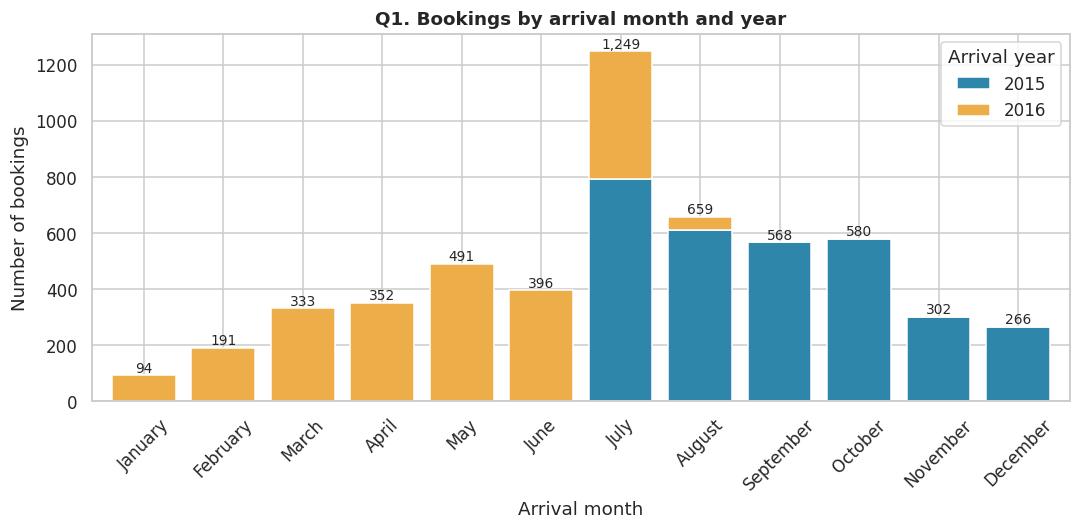

In [14]:
mv = df.groupby(["arrival_date_month", "arrival_date_year"], observed=False).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
mv.plot(kind="bar", stacked=True, ax=ax, color=[BLUE, ORANGE], width=0.8)
for i, t in enumerate(mv.sum(axis=1)):
    ax.text(i, t + 10, f"{t:,}", ha="center", fontsize=9)
ax.set_title("Q1. Bookings by arrival month and year")
ax.set_xlabel("Arrival month"); ax.set_ylabel("Number of bookings"); ax.legend(title="Arrival year")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
display(mv.assign(total=mv.sum(axis=1)))

**Interpretation:** July is the busiest arrival month (**1,249 bookings, 23% of the total**), followed by August (659), October (580) and September (568); January (94) and the winter months are the quietest, so demand follows a **summer-peak, winter-low** pattern typical of a resort.

**Justification and caution:** the file covers only July 2015 to early August 2016, so **only July appears in both years**. Months such as August (47 bookings in 2016, because the extract ends on 2 August) or January-June (2016 only) are not fully comparable. Month totals therefore show the shape of demand, not exact seasonal ratios.

### Question 2: Is the cancellation rate stable over time?
**Concept:** proportions and time-series comparison (checking whether the data are homogeneous before pooling them).

,cancelled,n,rate,lo,hi
arrival_date_year,,,,,
2015,1024,3122,0.328,0.312,0.345
2016,1710,2359,0.725,0.707,0.743


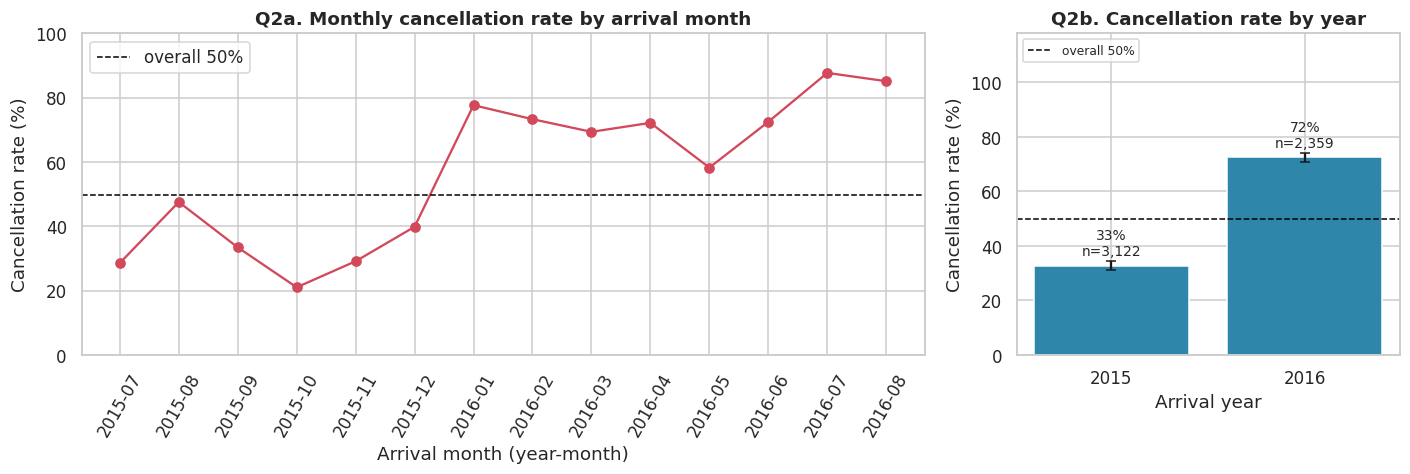

In [15]:
monthly = df.groupby("arrival_ym")["is_canceled"].agg(["mean", "size"])
by_year = rate_table(df, "arrival_date_year")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(monthly.index, monthly["mean"] * 100, marker="o", color=RED)
axes[0].axhline(OVERALL * 100, color="black", ls="--", lw=1, label=f"overall {OVERALL:.0%}")
axes[0].set_title("Q2a. Monthly cancellation rate by arrival month")
axes[0].set_xlabel("Arrival month (year-month)"); axes[0].set_ylabel("Cancellation rate (%)")
axes[0].tick_params(axis="x", rotation=60); axes[0].legend(); axes[0].set_ylim(0, 100)
plot_rate(axes[1], by_year, "Q2b. Cancellation rate by year", "Arrival year")
plt.tight_layout(); plt.show()
display(by_year)

**Interpretation:** the cancellation rate is **not stable**. In 2015 it was **32.8%** (1,024 of 3,122) and in 2016 **72.5%** (1,710 of 2,359). The monthly line shows the break clearly: it stays between 21% and 48% until December 2015 and jumps to 58-88% from January 2016. The confidence intervals do not overlap, so this is not random noise.

**Why it matters:** the overall 49.9% is an average of two very different periods. Every later result that mixes both years has to be read with this in mind, which is why the year effect is tested formally (H4), why arrival year is kept out of the prediction model, and why the model is also validated on a later time period (Section 7).

### Question 3: What does the lead-time distribution look like?
**Concept:** descriptive statistics - mean, median, standard deviation, skewness, kurtosis, percentiles.

,lead_time (days)
mean,90.435
median,68.000
std,80.921
skewness,1.240
kurtosis,2.004
Q1,28.000
Q3,135.000
95th percentile,251.000
max,737.000


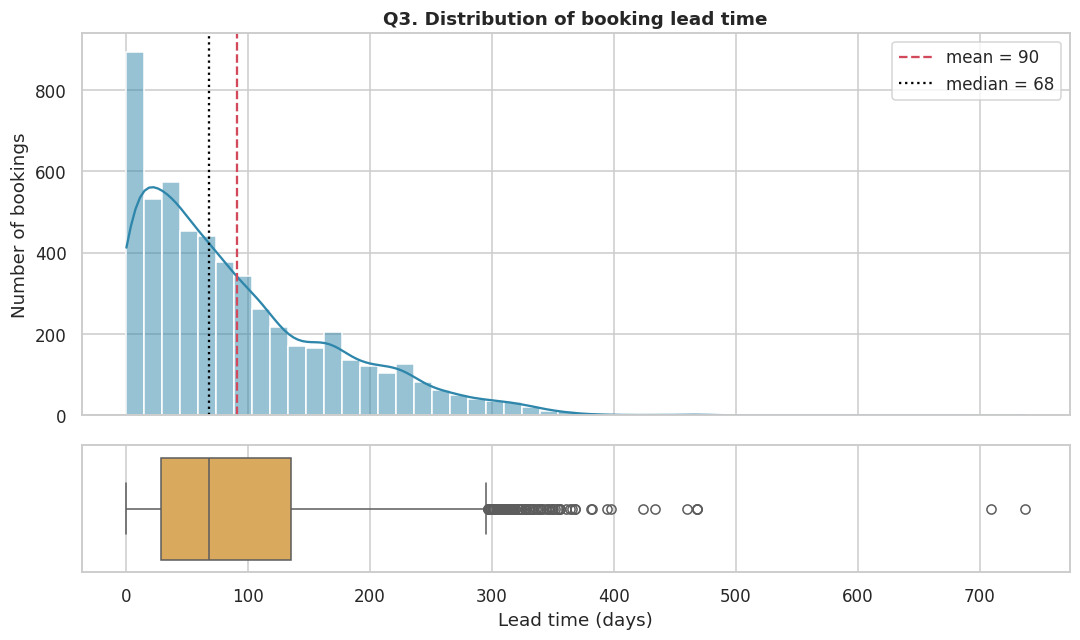

In [16]:
x = df["lead_time"]
summ = pd.Series({"mean": x.mean(), "median": x.median(), "std": x.std(), "skewness": x.skew(),
                  "kurtosis": x.kurt(), "Q1": x.quantile(.25), "Q3": x.quantile(.75),
                  "95th percentile": x.quantile(.95), "max": x.max()})
display(summ.to_frame("lead_time (days)"))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
sns.histplot(x, bins=50, kde=True, color=BLUE, ax=axes[0])
axes[0].axvline(x.mean(), color=RED, ls="--", label=f"mean = {x.mean():.0f}")
axes[0].axvline(x.median(), color="black", ls=":", label=f"median = {x.median():.0f}")
axes[0].set_title("Q3. Distribution of booking lead time"); axes[0].set_ylabel("Number of bookings"); axes[0].legend()
sns.boxplot(x=x, color=ORANGE, ax=axes[1]); axes[1].set_xlabel("Lead time (days)")
plt.tight_layout(); plt.show()

**Interpretation:** the **mean lead time is 90.4 days but the median is only 68 days**, and the standard deviation (80.9) is almost as large as the mean. Skewness of 1.24 confirms a long right tail: a quarter of guests book within 28 days, a quarter book more than 135 days ahead, 5% book more than 251 days (over 8 months) ahead, and the longest lead time is 737 days.

**Justification:** because the distribution is skewed, the **median (68 days)** is the better summary of a typical booking, and non-parametric tests are used alongside t-tests when lead time is compared (H1).

### Question 4: Do cancelled and non-cancelled bookings differ in lead time?
**Concept:** grouped descriptive statistics and distribution comparison (formal test in H1).

,count,mean,std,min,25%,50%,75%,max
cancel_label,,,,,,,,
Cancelled,"2,734.000",90.206,75.072,0.000,33.000,72.000,127.750,468.000
Not cancelled,"2,747.000",90.662,86.363,0.000,21.500,65.000,142.500,737.000


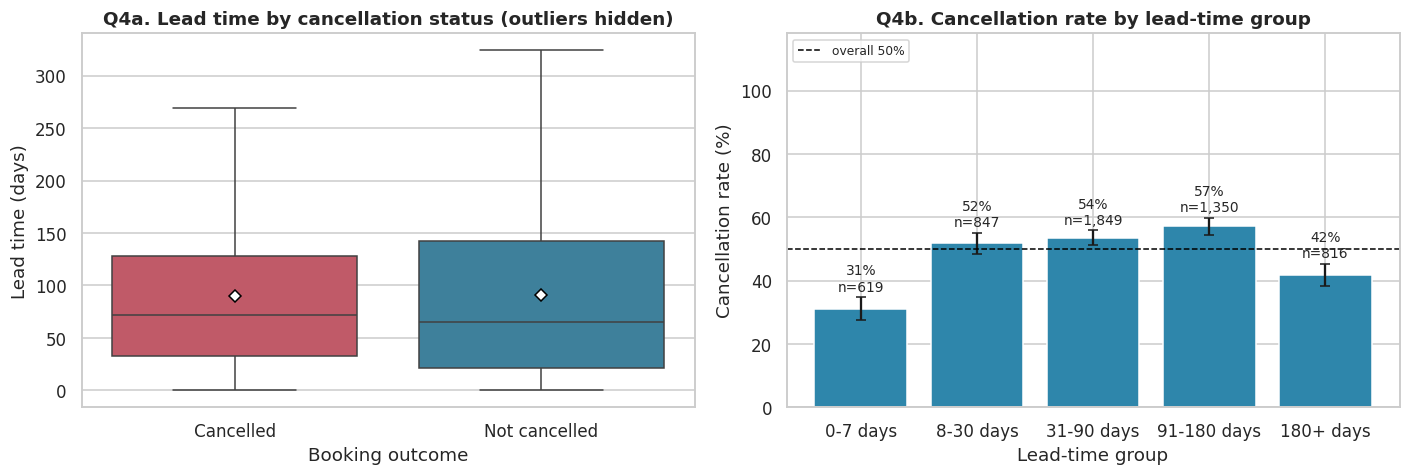

In [17]:
display(df.groupby("cancel_label")["lead_time"].describe())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="cancel_label", y="lead_time", showmeans=True, showfliers=False, palette=[RED, BLUE],
            order=["Cancelled", "Not cancelled"], ax=axes[0],
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[0].set_title("Q4a. Lead time by cancellation status (outliers hidden)")
axes[0].set_xlabel("Booking outcome"); axes[0].set_ylabel("Lead time (days)")
plot_rate(axes[1], rate_table(df, "lead_group"), "Q4b. Cancellation rate by lead-time group", "Lead-time group")
plt.tight_layout(); plt.show()

**Interpretation:** the **average lead time is almost identical** for cancelled (90.2 days) and non-cancelled bookings (90.7 days). The medians differ slightly (72 vs 65 days), and non-cancelled bookings are *more spread out* (IQR 21-143 days against 33-128 days). The right-hand chart explains why the averages hide the story: the cancellation rate is **not a straight line** in lead time. It is lowest for last-minute bookings (0-7 days: **31%**), peaks for bookings made 91-180 days ahead (**57%**) and falls again for bookings made more than 180 days ahead (**42%**).

**Justification:** a relationship that rises and then falls cannot be captured by a simple mean comparison or a correlation coefficient. Lead time is therefore a **weak stand-alone signal** (see H1 and Q10), even though groups defined by lead time do differ.

### Question 5: Which market segments cancel the most?
**Concept:** conditional proportions with confidence intervals (association tested in H3).

,cancelled,n,rate,lo,hi
market_segment,,,,,
Online TA,1831,2945,0.622,0.604,0.639
Complementary,7,15,0.467,0.248,0.699
Direct,311,739,0.421,0.386,0.457
Corporate,83,206,0.403,0.338,0.471
Groups,167,481,0.347,0.306,0.391
Offline TA/TO,335,1095,0.306,0.279,0.334


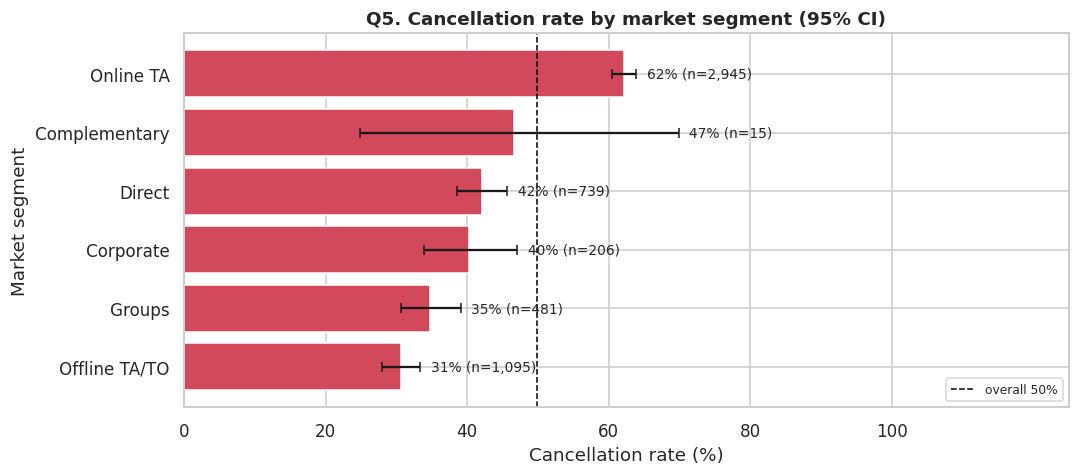

In [18]:
g = rate_table(df, "market_segment").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_rate(ax, g, "Q5. Cancellation rate by market segment (95% CI)", "Market segment", horizontal=True, color=RED)
plt.tight_layout(); plt.show()
display(g)

**Interpretation:** **Online TA bookings cancel most (62.2%, n = 2,945)**, clearly above the overall 49.9% line. Offline agents have the lowest rate (30.6%), and Groups (34.7%), Corporate (40.3%) and Direct (42.1%) lie in between. The Complementary segment (46.7%) has only 15 bookings, so its wide confidence interval (25%-70%) means it should not be over-interpreted.

**Justification:** Online TA is both the largest channel (54% of bookings) and the riskiest one, so it has the biggest influence on total cancellations. This is tested formally in H3.

### Question 6: How does the deposit type relate to cancellation?
**Concept:** contingency table and conditional proportions (chi-square test in H2).

cancel_label,Cancelled,Not cancelled,All
deposit_type,,,
No Deposit,2662,2697,5359
Non Refund,70,11,81
Refundable,2,39,41
All,2734,2747,5481


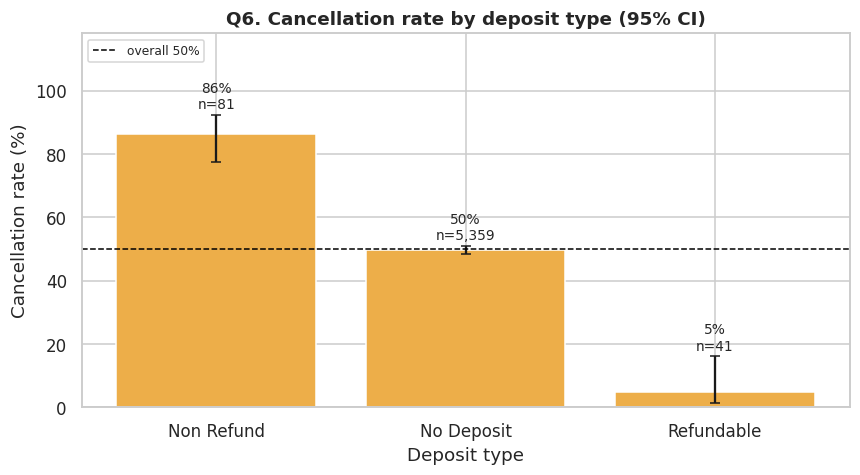

In [19]:
g = rate_table(df, "deposit_type").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_rate(ax, g, "Q6. Cancellation rate by deposit type (95% CI)", "Deposit type", color=ORANGE)
plt.tight_layout(); plt.show()
display(pd.crosstab(df["deposit_type"], df["cancel_label"], margins=True))

**Interpretation:** the pattern is strong but **counter-intuitive**. Bookings with a **non-refundable deposit cancelled 86.4% of the time (70 of 81)**, far above no-deposit bookings (49.7%), while **refundable** deposits show only **4.9%** (2 of 41). One would expect non-refundable bookings to be the most committed guests.

**Justification and caution:** 98% of bookings are "No Deposit", so the two special groups are very small (81 and 41 bookings). A likely explanation is that this label records how the booking was *classified*, not the guest's intention; the result needs checking against the hotel's records before any policy is based on it. Association is tested in H2.

### Question 7: How do customer types differ in cancellation behaviour and price?
**Concept:** group comparison of a proportion and a numeric variable (ANOVA in H6).

,count,mean,median,std
customer_type,,,,
Transient,4370,105.004,96.300,53.206
Transient-Party,700,73.710,66.000,38.119
Contract,268,75.047,70.395,30.893
Group,10,96.690,85.100,44.753


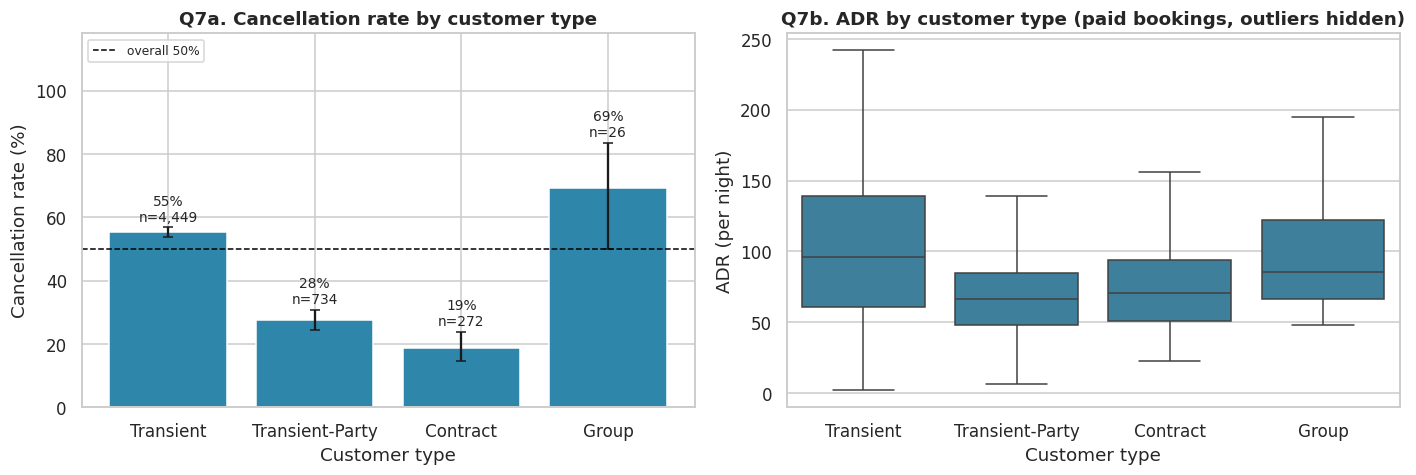

In [20]:
paid = df[df["adr"] > 0]
order = ["Transient", "Transient-Party", "Contract", "Group"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_rate(axes[0], rate_table(df, "customer_type").loc[order], "Q7a. Cancellation rate by customer type", "Customer type")
sns.boxplot(data=paid, x="customer_type", y="adr", order=order, color=BLUE, showfliers=False, ax=axes[1])
axes[1].set_title("Q7b. ADR by customer type (paid bookings, outliers hidden)")
axes[1].set_xlabel("Customer type"); axes[1].set_ylabel("ADR (per night)")
plt.tight_layout(); plt.show()
display(paid.groupby("customer_type")["adr"].agg(["count", "mean", "median", "std"]).loc[order])

**Interpretation:** customer type is linked with both behaviour and price. **Transient** (individual) travellers cancel **55.4%** of the time, **Transient-Party 27.5%** and **Contract 18.8%**; the Group type has the highest rate (69%) but only 26 bookings. Transient guests also pay the most (mean ADR **105.0** vs 73.7 for Transient-Party and 75.0 for Contract), so the most price-sensitive revenue is also the most likely to cancel.

**Justification:** the Group type has only 10 paid bookings, so it is excluded from conclusions. The ADR difference is tested with ANOVA in H6.

### Question 8: Do guests who make special requests cancel less?
**Concept:** comparing proportions between groups - the basis for the A/B test in H5.

,cancelled,n,rate,lo,hi
requests_grp,,,,,
0,1581,2975,0.531,0.513,0.549
1,749,1573,0.476,0.452,0.501
2,349,785,0.445,0.410,0.480
3+,55,148,0.372,0.298,0.452


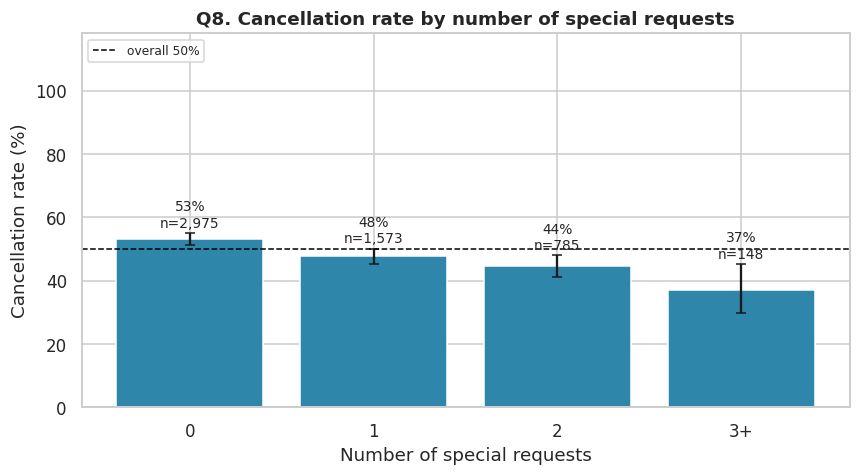

In [21]:
df["requests_grp"] = df["total_of_special_requests"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
g = rate_table(df, "requests_grp").loc[["0", "1", "2", "3+"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_rate(ax, g, "Q8. Cancellation rate by number of special requests", "Number of special requests", color=BLUE)
plt.tight_layout(); plt.show()
display(g)

**Interpretation:** the cancellation rate **falls steadily as the number of special requests rises**: 53.1% with no request, 47.6% with one, 44.5% with two and 37.2% with three or more. Guests who ask for something (a cot, a sea view, a late check-in) appear to be more committed.

**Justification:** a "dose-response" pattern (the more requests, the lower the cancellation) makes the relationship more believable than a single gap would. It is tested as an A/B comparison in H5.

### Question 9: How does price (ADR) change through the year?
**Concept:** seasonality of a numeric variable; comparison of central tendency across months.

,mean,sem,count
season,,,
Winter,60.746,1.426,533
Spring,69.002,0.729,1151
Summer,139.921,0.988,2268
Autumn,73.357,0.902,1396


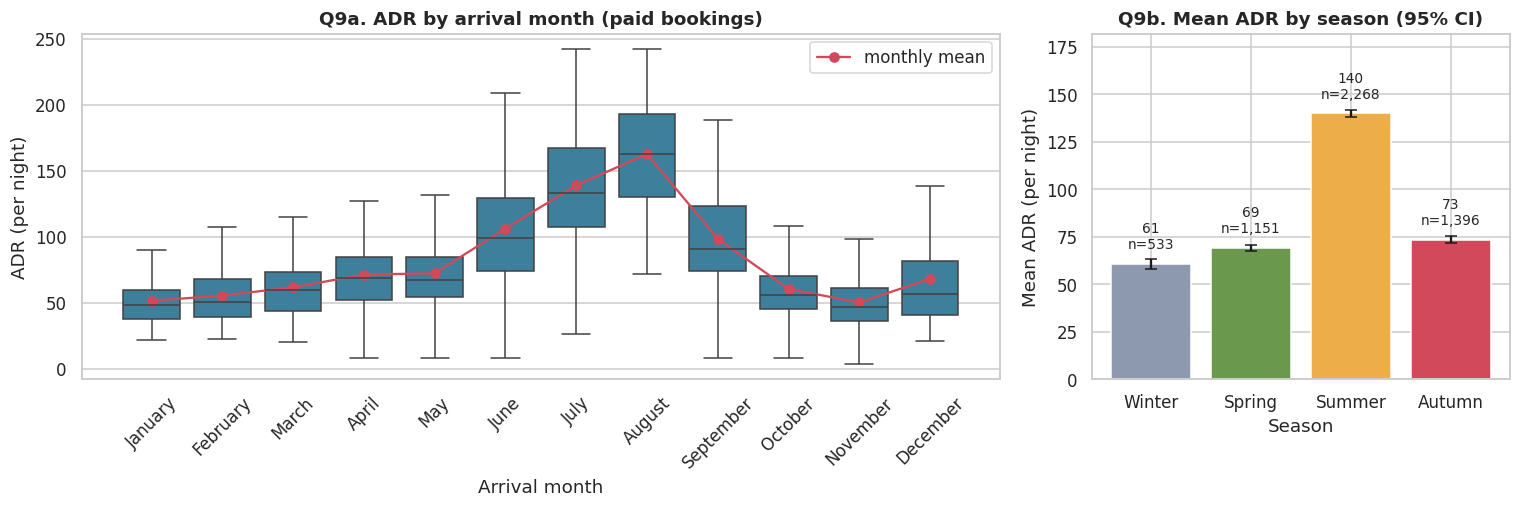

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
sns.boxplot(data=paid, x="arrival_date_month", y="adr", color=BLUE, showfliers=False, ax=axes[0])
axes[0].plot(range(12), paid.groupby("arrival_date_month", observed=False)["adr"].mean().values,
             color=RED, marker="o", label="monthly mean")
axes[0].set_title("Q9a. ADR by arrival month (paid bookings)"); axes[0].set_xlabel("Arrival month"); axes[0].set_ylabel("ADR (per night)")
axes[0].tick_params(axis="x", rotation=45); axes[0].legend()
s = paid.groupby("season")["adr"].agg(["mean", "sem", "count"]).loc[["Winter", "Spring", "Summer", "Autumn"]]
axes[1].bar(s.index, s["mean"], yerr=1.96 * s["sem"], color=[GREY, "#6a994e", ORANGE, RED], capsize=4)
for i, (mu, n) in enumerate(zip(s["mean"], s["count"])): axes[1].text(i, mu + 8, f"{mu:.0f}\nn={n:,}", ha="center", fontsize=9)
axes[1].set_title("Q9b. Mean ADR by season (95% CI)"); axes[1].set_xlabel("Season"); axes[1].set_ylabel("Mean ADR (per night)")
axes[1].set_ylim(0, s["mean"].max() * 1.3)
plt.tight_layout(); plt.show()
display(s)

**Interpretation:** price is strongly seasonal. Mean ADR climbs from about **51 in January** to **139 in July and 163 in August**, then drops back to about 50-60 in October-November. By season: Winter 60.7, Spring 69.0, **Summer 139.9**, Autumn 73.4. Summer prices are therefore **about twice** those of the rest of the year, and the 95% confidence intervals of the seasons barely overlap.

**Justification and caution:** because 2015 and 2016 are mixed (the July mean was 128 in 2015 and 158 in 2016) part of the monthly pattern also reflects price growth over time. The summer premium is tested in H7.

### Question 10: Which numeric variables are related to each other?
**Concept:** correlation analysis - Pearson (linear) and Spearman (rank-based, robust to skew).

Strongest correlations with cancellation (Spearman):


,rho
required_car_parking_spaces,-0.321
booking_changes,-0.193
adr,0.126
total_of_special_requests,-0.077
days_in_waiting_list,-0.069
total_guests,0.064
lead_time,0.044
total_nights,0.026


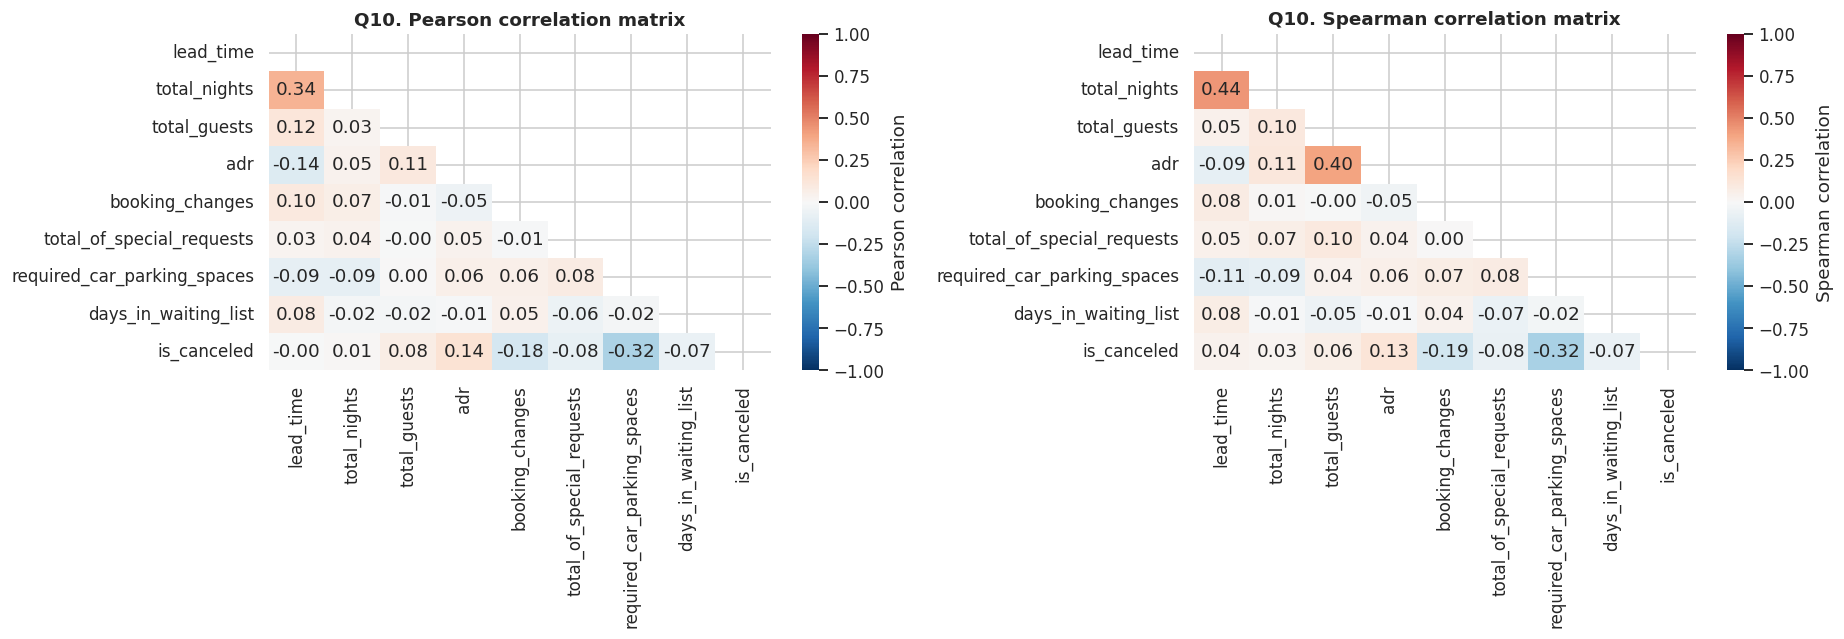

In [23]:
cols = ["lead_time", "total_nights", "total_guests", "adr", "booking_changes", "total_of_special_requests",
        "required_car_parking_spaces", "days_in_waiting_list", "is_canceled"]
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    cm = df[cols].corr(method=method)
    sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool)), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, ax=ax, cbar_kws={"label": f"{method.title()} correlation"})
    ax.set_title(f"Q10. {method.title()} correlation matrix")
plt.tight_layout(); plt.show()
print("Strongest correlations with cancellation (Spearman):")
display(df[cols].corr(method="spearman")["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False).to_frame("rho"))

**Interpretation:** correlations between the numeric variables are modest. The relationship with cancellation is strongest for **required parking spaces (rho = -0.32)** and **booking changes (-0.19)**: guests who plan to drive and park, or who modify their booking, are more committed. Higher ADR is weakly linked to more cancellation (+0.13), and lead time (+0.04) and nights (+0.03) are almost unrelated to it. Among the other variables, longer lead times go with longer stays (r = 0.34), and higher ADR with shorter lead time (-0.14).

**Justification:** Spearman is shown next to Pearson because most variables are skewed or count data. Predictors are not strongly correlated with each other (the VIF check in Section 7 is below 1.3), which is good for regression.

### Question 11: What is the probability distribution of the length of stay?
**Concept:** discrete random variable - probability mass function (PMF), cumulative distribution function (CDF), expected value and variance.

E[X] = 4.96 nights,  Var[X] = 12.01,  SD = 3.47
P(X > 5)  = 0.397
P(X <= 3) = 0.394
P(X = 7)  = 0.202   (most common single value: 7 nights)


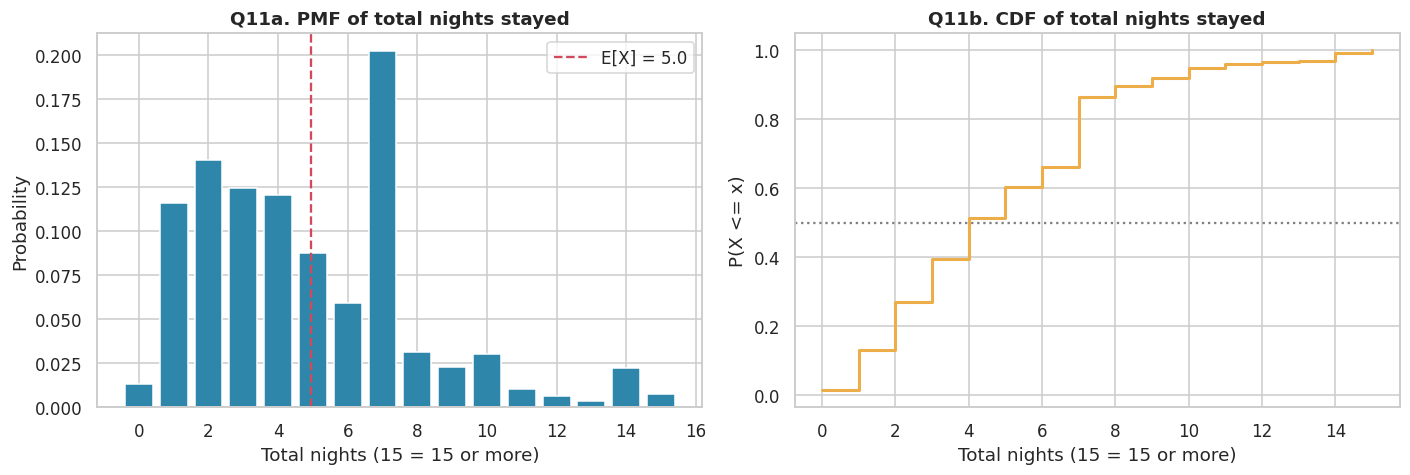

In [24]:
nights = df["total_nights"]
pmf = nights.clip(upper=15).value_counts(normalize=True).sort_index()   # 15 = "15 or more"
cdf = pmf.cumsum()
EX, VarX = nights.mean(), nights.var()
print(f"E[X] = {EX:.2f} nights,  Var[X] = {VarX:.2f},  SD = {np.sqrt(VarX):.2f}")
print(f"P(X > 5)  = {(nights > 5).mean():.3f}")
print(f"P(X <= 3) = {(nights <= 3).mean():.3f}")
print(f"P(X = 7)  = {(nights == 7).mean():.3f}   (most common single value: {nights.mode()[0]} nights)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(pmf.index, pmf.values, color=BLUE)
axes[0].axvline(EX, color=RED, ls="--", label=f"E[X] = {EX:.1f}")
axes[0].set_title("Q11a. PMF of total nights stayed"); axes[0].set_xlabel("Total nights (15 = 15 or more)"); axes[0].set_ylabel("Probability"); axes[0].legend()
axes[1].step(cdf.index, cdf.values, where="post", color=ORANGE, lw=2)
axes[1].axhline(0.5, color="gray", ls=":"); axes[1].set_title("Q11b. CDF of total nights stayed")
axes[1].set_xlabel("Total nights (15 = 15 or more)"); axes[1].set_ylabel("P(X <= x)")
plt.tight_layout(); plt.show()

**Interpretation:** the expected length of stay is **E[X] = 4.96 nights** (variance 12.0, SD 3.5). The distribution is right-skewed: the median is 4 nights, **7 nights is the most common stay (20.2%)** - a weekly package pattern - and **P(X > 5) = 39.7%**, **P(X <= 3) = 39.4%**. Very long stays (15+ nights) are rare.

**Justification:** treating nights as a discrete random variable gives probabilities that can be used directly, for example to plan housekeeping and room-release decisions around the 1-7 night range that covers most bookings.

### Question 12: How much does knowing the lead time or channel change the cancellation probability?
**Concept:** conditional probability, lift and **Bayes' theorem**.

P(Online TA) = 0.537;  P(Cancelled | Online TA) = 0.622;  P(Cancelled) = 0.499
Bayes:  P(Online TA | Cancelled) = 0.670   (direct count check: 0.670)


,P(Cancel | condition),Lift vs overall
All bookings,0.499,1.000
Lead time > 60 days,0.518,1.039
Lead time <= 60 days,0.476,0.954
Online TA,0.622,1.246
Offline TA/TO,0.306,0.613
Non-refundable deposit,0.864,1.733
At least 1 special request,0.460,0.922
Portugal (PRT),0.725,1.454


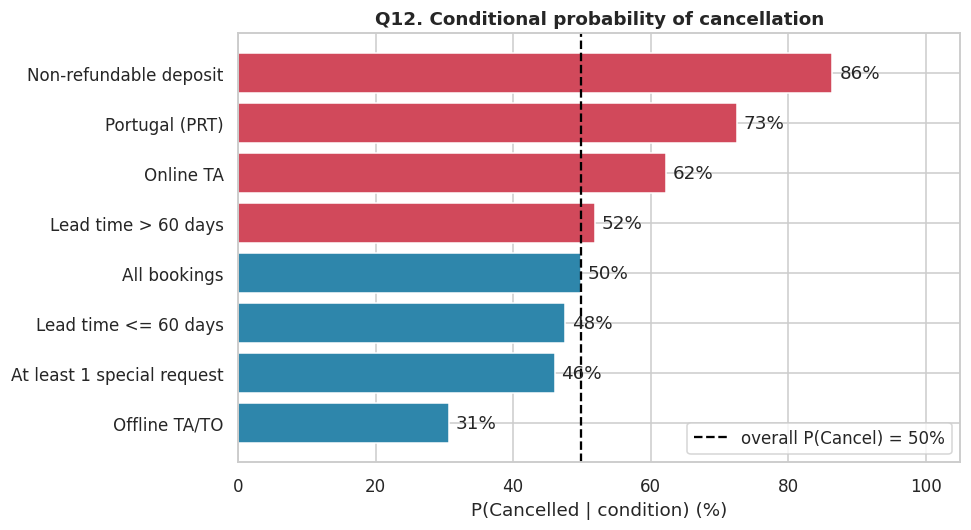

In [25]:
P_C = df["is_canceled"].mean()
cond = {
    "All bookings": P_C,
    "Lead time > 60 days": df.loc[df["lead_time"] > 60, "is_canceled"].mean(),
    "Lead time <= 60 days": df.loc[df["lead_time"] <= 60, "is_canceled"].mean(),
    "Online TA": df.loc[df["market_segment"] == "Online TA", "is_canceled"].mean(),
    "Offline TA/TO": df.loc[df["market_segment"] == "Offline TA/TO", "is_canceled"].mean(),
    "Non-refundable deposit": df.loc[df["deposit_type"] == "Non Refund", "is_canceled"].mean(),
    "At least 1 special request": df.loc[df["has_request"] == 1, "is_canceled"].mean(),
    "Portugal (PRT)": df.loc[df["country"] == "PRT", "is_canceled"].mean(),
}
cp = pd.Series(cond).to_frame("P(Cancel | condition)")
cp["Lift vs overall"] = cp["P(Cancel | condition)"] / P_C
display(cp)

# Bayes' theorem: P(Online TA | Cancelled) = P(Cancelled | Online TA) * P(Online TA) / P(Cancelled)
P_ota = (df["market_segment"] == "Online TA").mean()
P_C_given_ota = cond["Online TA"]
bayes = P_C_given_ota * P_ota / P_C
direct = (df.loc[df["is_canceled"] == 1, "market_segment"] == "Online TA").mean()
print(f"P(Online TA) = {P_ota:.3f};  P(Cancelled | Online TA) = {P_C_given_ota:.3f};  P(Cancelled) = {P_C:.3f}")
print(f"Bayes:  P(Online TA | Cancelled) = {bayes:.3f}   (direct count check: {direct:.3f})")

fig, ax = plt.subplots(figsize=(9, 5))
cp_plot = cp["P(Cancel | condition)"].sort_values()
ax.barh(cp_plot.index, cp_plot.values * 100, color=[RED if v > P_C else BLUE for v in cp_plot.values])
ax.axvline(P_C * 100, color="black", ls="--", label=f"overall P(Cancel) = {P_C:.0%}")
for i, v in enumerate(cp_plot.values): ax.text(v * 100 + 1, i, f"{v:.0%}", va="center")
ax.set_title("Q12. Conditional probability of cancellation"); ax.set_xlabel("P(Cancelled | condition) (%)"); ax.set_xlim(0, 105); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretation:**
- Knowing the **lead time barely changes the odds**: P(Cancel | lead > 60 days) = 51.8% against 47.6% for shorter lead times (lift about 1.04), in line with Q4 and H1.
- Knowing the **channel or country changes them a lot**: Online TA 62.2% (lift 1.25), Portugal 72.5% (1.45), non-refundable deposit 86.4% (1.73), while Offline TA/TO (30.6%) and guests with special requests (46.0%) are below average.
- **Bayes' theorem:** P(Online TA | Cancelled) = 0.622 x 0.537 / 0.499 = **0.670**. So **two-thirds of all cancellations come from Online TA bookings**, although they are only 54% of bookings. The direct count (0.670) confirms the calculation.

**Justification:** conditional probability answers the practical question "given what I know when the booking arrives, how likely is it to be cancelled?", and Bayes' theorem reverses it to "who are the people who cancel?".

### Question 13: Where do guests come from and do domestic and international guests cancel differently?
**Concept:** frequency analysis and conditional proportions by country.

,cancelled,n,rate,lo,hi
country_grp,,,,,
International,334,2171,0.154,0.139,0.170
Portugal,2400,3310,0.725,0.710,0.740


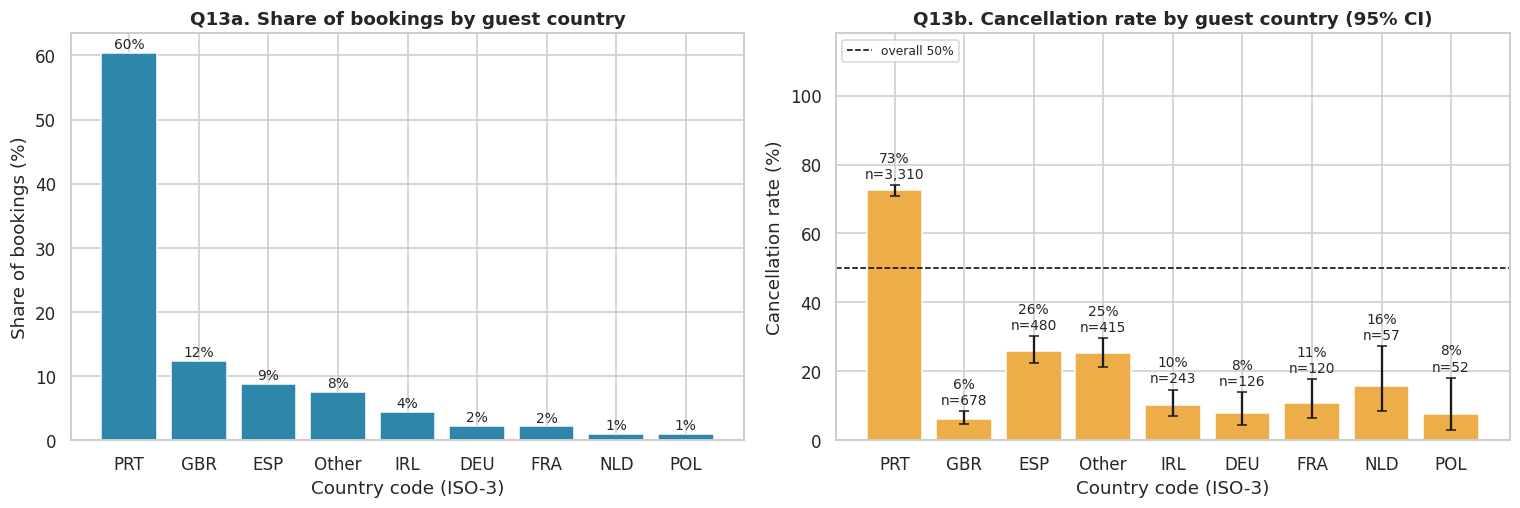

In [26]:
top = df["country"].value_counts().head(8).index
df["country_top"] = np.where(df["country"].isin(top), df["country"], "Other")
cnt = df["country_top"].value_counts()
g = rate_table(df, "country_top").loc[cnt.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(cnt.index, cnt.values / len(df) * 100, color=BLUE)
for i, v in enumerate(cnt.values): axes[0].text(i, v / len(df) * 100 + 0.7, f"{v/len(df):.0%}", ha="center", fontsize=9)
axes[0].set_title("Q13a. Share of bookings by guest country"); axes[0].set_xlabel("Country code (ISO-3)"); axes[0].set_ylabel("Share of bookings (%)")
plot_rate(axes[1], g, "Q13b. Cancellation rate by guest country (95% CI)", "Country code (ISO-3)", color=ORANGE)
plt.tight_layout(); plt.show()
display(rate_table(df, "country_grp"))

**Interpretation:** the resort depends on domestic guests: **Portugal supplies 60% of bookings**, followed by the United Kingdom (12%), Spain (9%) and Ireland (4%). Their cancellation behaviour is very different. **Portuguese guests cancel 72.5%** of the time against **15.4% for all international guests** combined (UK 6.3%, Germany 7.9%, Ireland 10.3%, France 10.8%, Spain 26%).

**Justification and caution:** this is the largest single difference found in the data (risk ratio 4.7, tested in H9). It remains large within each year, but because the overall cancellation rate also changed over time (Q2) and international guests almost never cancelled in 2015, the size of this gap should be validated on the full dataset.

### Question 14: Can the average price be estimated reliably from samples?
**Concept:** sampling distribution, **Central Limit Theorem** and confidence interval for a mean.

Population (paid bookings): N=5,348, mean=99.39, SD=51.92, skewness=0.78
One sample of 100 bookings: mean = 104.13, 95% CI = (93.26, 115.00)  -> contains true mean 99.39? True


,mean of sample means,SD of sample means,theory: sigma/sqrt(n),skewness of means
n,,,,
5,99.359,23.453,23.220,0.319
30,99.401,9.517,9.480,0.109
100,99.225,5.201,5.192,0.078


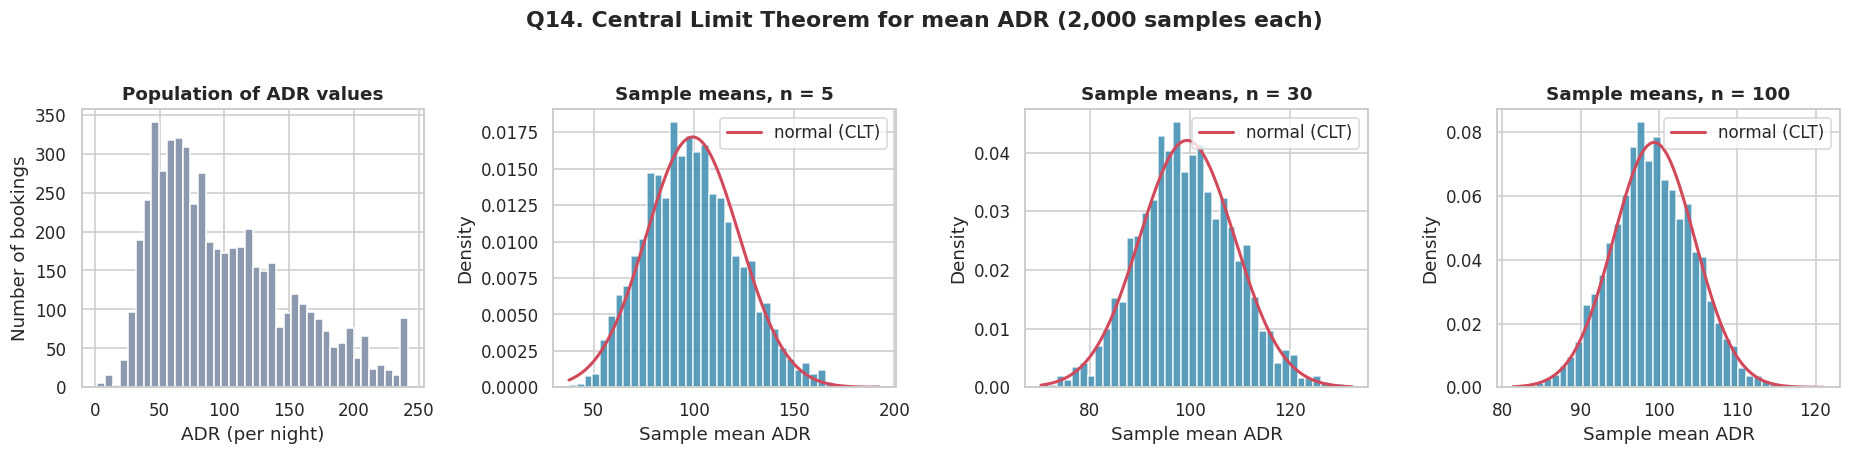

In [27]:
pop = paid["adr"].values
print(f"Population (paid bookings): N={len(pop):,}, mean={pop.mean():.2f}, SD={pop.std(ddof=1):.2f}, skewness={stats.skew(pop):.2f}")
rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].hist(pop, bins=40, color=GREY); axes[0].set_title("Population of ADR values"); axes[0].set_xlabel("ADR (per night)"); axes[0].set_ylabel("Number of bookings")
rows = []
for ax, n in zip(axes[1:], [5, 30, 100]):
    means = rng.choice(pop, size=(2000, n), replace=True).mean(axis=1)
    ax.hist(means, bins=40, density=True, color=BLUE, alpha=.8)
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, pop.mean(), pop.std(ddof=1) / np.sqrt(n)), color=RED, lw=2, label="normal (CLT)")
    ax.set_title(f"Sample means, n = {n}"); ax.set_xlabel("Sample mean ADR"); ax.set_ylabel("Density"); ax.legend()
    rows.append({"n": n, "mean of sample means": means.mean(), "SD of sample means": means.std(ddof=1),
                 "theory: sigma/sqrt(n)": pop.std(ddof=1) / np.sqrt(n), "skewness of means": stats.skew(means)})
plt.suptitle("Q14. Central Limit Theorem for mean ADR (2,000 samples each)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("n"))
one = rng.choice(pop, size=100, replace=False)
ci = stats.t.interval(0.95, df=99, loc=one.mean(), scale=stats.sem(one))
print(f"One sample of 100 bookings: mean = {one.mean():.2f}, 95% CI = ({ci[0]:.2f}, {ci[1]:.2f})  -> contains true mean {pop.mean():.2f}? {ci[0] <= pop.mean() <= ci[1]}")

**Interpretation:** ADR is right-skewed (skewness 0.78), yet the **sampling distribution of the mean becomes normal as the sample size grows**: skewness of the sample means falls from 0.32 (n = 5) to 0.11 (n = 30) to 0.08 (n = 100), and the red normal curves fit the histograms well. The standard deviation of the sample means (23.5, 9.5, 5.2) matches the theoretical sigma/sqrt(n) (23.2, 9.5, 5.2) almost exactly.

**Practical use:** a random sample of only 100 bookings estimated the mean ADR as 104.1 with a 95% confidence interval of **(93.3, 115.0)**, which contains the true value of 99.4. So the hotel can estimate its average price within about +/-11% from a small sample, even though individual prices are skewed.

### Question 15: Do families with children differ from other guests?
**Concept:** group comparison on several variables (price tested in H8).

,bookings,mean_adr,mean_nights,cancel_rate
group,,,,
With children/babies,658,143.311,5.068,0.602
Without children,4823,90.659,4.944,0.485


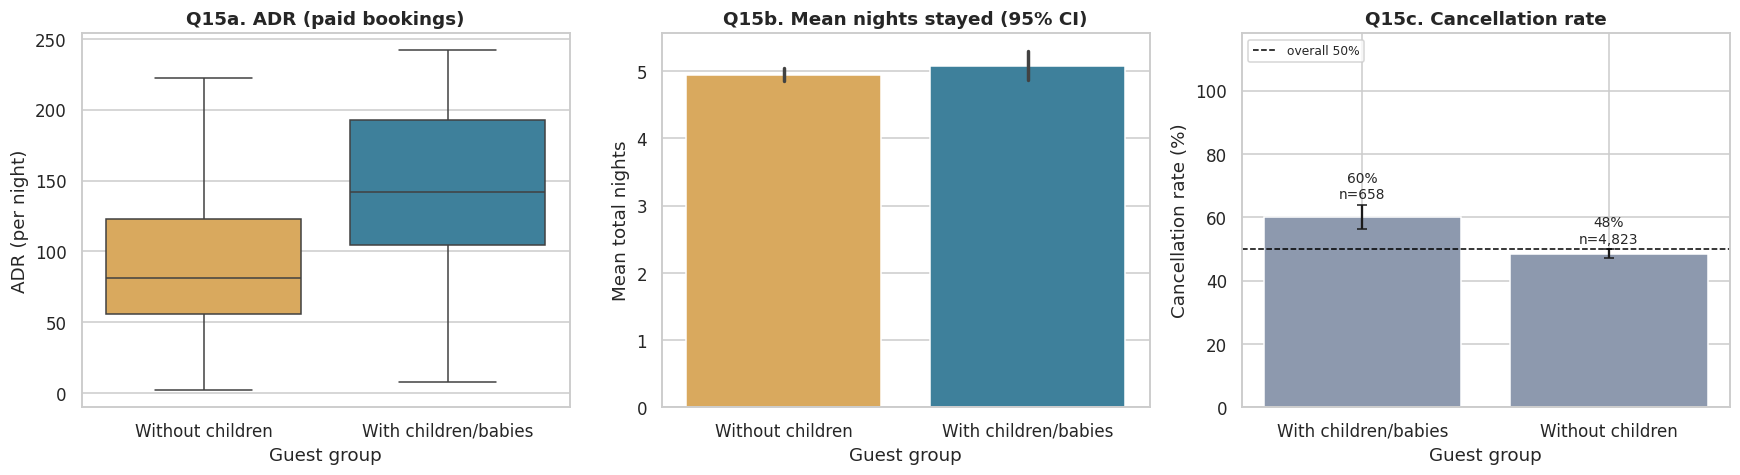

In [28]:
fam = df.assign(group=np.where(df["has_children"] == 1, "With children/babies", "Without children"))
fam_paid = fam[fam["adr"] > 0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=fam_paid, x="group", y="adr", showfliers=False, palette=[ORANGE, BLUE], ax=axes[0])
axes[0].set_title("Q15a. ADR (paid bookings)"); axes[0].set_xlabel("Guest group"); axes[0].set_ylabel("ADR (per night)")
sns.barplot(data=fam, x="group", y="total_nights", palette=[ORANGE, BLUE], errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("Q15b. Mean nights stayed (95% CI)"); axes[1].set_xlabel("Guest group"); axes[1].set_ylabel("Mean total nights")
plot_rate(axes[2], rate_table(fam, "group"), "Q15c. Cancellation rate", "Guest group", color=GREY)
plt.tight_layout(); plt.show()
display(fam.groupby("group").agg(bookings=("is_canceled", "size"), mean_adr=("adr", "mean"),
                                 mean_nights=("total_nights", "mean"), cancel_rate=("is_canceled", "mean")))

**Interpretation:** bookings with children or babies (658, 12% of the total) pay a **much higher price per night** (mean ADR about 143-145 vs 91-93, roughly +56%) and cancel more often (**60.2% vs 48.5%**), but stay about the same number of nights (5.1 vs 4.9).

**Justification:** families are a valuable segment (higher revenue per night) but a riskier one, so a family-specific policy such as a deposit or flexible rebooking could protect the extra revenue. The price difference is tested in H8.

## 6. Hypothesis Testing and A/B Testing

For every test: hypotheses are stated, the **assumptions are checked to justify the choice of test**, the p-value and an **effect size** are reported (a tiny p-value on a large sample can hide a trivial effect), and a decision is made at α = 0.05. Because nine tests are run together, the p-values are also adjusted with the **Holm correction** to control the chance of false positives.

> **Note on A/B testing.** The groups below are natural groups in historical data, not randomly assigned. The test shows whether the difference is real, but it cannot prove cause and effect. A true A/B experiment would randomise the groups, for example by testing a new deposit policy on half of the bookings.

In [29]:
ALPHA = 0.05
results = []   # collected for the summary table

def two_prop(k1, n1, k2, n2, alt="two-sided"):
    """Two-proportion z-test (pooled SE for the test, unpooled SE for the CI of the difference)."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    p = {"two-sided": 2 * stats.norm.sf(abs(z)), "greater": stats.norm.sf(z), "less": stats.norm.cdf(z)}[alt]
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {"p1": p1, "p2": p2, "diff": p1 - p2, "z": z, "p": p, "ci": (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se), "rr": p1 / p2}

def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

def cohens_d(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)

def record(code, hypothesis, test, stat, p, effect_name, effect):
    results.append({"ID": code, "Question": hypothesis, "Test": test, "Statistic": stat, "p-value": p,
                    "Effect size": f"{effect_name} = {effect:.3f}"})

### H1 - Does lead time differ between cancelled and non-cancelled bookings? (Q4)
- **H0:** mean lead time is the same for cancelled and non-cancelled bookings.  **H1:** the means differ.
- **Test choice:** compare two independent groups on a numeric variable. Normality and equal variance are checked first.

Normality (D'Agostino): cancelled p=1.47e-118, not cancelled p=9.26e-126  | skewness 1.24 / 1.23
Equal variance (Levene): p = 0.0000
Means: cancelled = 90.2 days, not cancelled = 90.7 days
Welch t-test: t = -0.208, p = 0.8349,  Cohen's d = -0.006
Mann-Whitney U: p = 0.0011,  rank-biserial r = 0.051


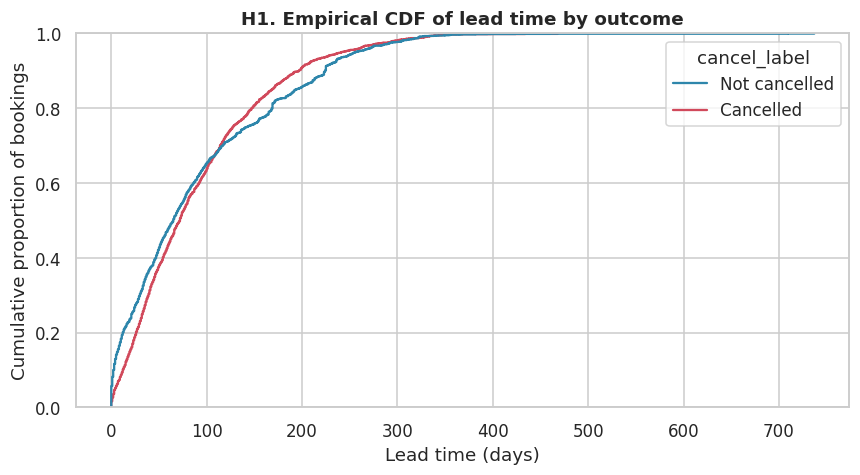

In [30]:
a = df.loc[df["is_canceled"] == 1, "lead_time"]; b = df.loc[df["is_canceled"] == 0, "lead_time"]
print(f"Normality (D'Agostino): cancelled p={stats.normaltest(a).pvalue:.2e}, not cancelled p={stats.normaltest(b).pvalue:.2e}  | skewness {a.skew():.2f} / {b.skew():.2f}")
print(f"Equal variance (Levene): p = {stats.levene(a, b).pvalue:.4f}")
t = stats.ttest_ind(a, b, equal_var=False)                       # Welch: robust to unequal variances; n is large
u = stats.mannwhitneyu(a, b, alternative="two-sided")           # rank-based check because lead time is skewed
d = cohens_d(a, b); rbc = 2 * u.statistic / (len(a) * len(b)) - 1
print(f"Means: cancelled = {a.mean():.1f} days, not cancelled = {b.mean():.1f} days")
print(f"Welch t-test: t = {t.statistic:.3f}, p = {t.pvalue:.4f},  Cohen's d = {d:.3f}")
print(f"Mann-Whitney U: p = {u.pvalue:.4f},  rank-biserial r = {rbc:.3f}")
record("H1", "Lead time differs by cancellation", "Welch t-test", t.statistic, t.pvalue, "Cohen d", d)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.ecdfplot(data=df, x="lead_time", hue="cancel_label", palette={"Cancelled": RED, "Not cancelled": BLUE}, ax=ax)
ax.set_title("H1. Empirical CDF of lead time by outcome"); ax.set_xlabel("Lead time (days)"); ax.set_ylabel("Cumulative proportion of bookings")
plt.tight_layout(); plt.show()

**Decision: fail to reject H0 (Welch p = 0.83).** The mean lead times (90.2 vs 90.7 days) are statistically indistinguishable and Cohen's d = -0.006 is essentially zero.

**Justification:** both groups are strongly skewed (normality rejected) and their variances differ (Levene p < 0.001), so the Welch t-test (which does not assume equal variances) was used and, because the sample is large, the mean is still reliable. The rank-based Mann-Whitney test does find a *distribution* difference (p = 0.001) but the effect is tiny (rank-biserial r = 0.05) and matches the pattern seen in Q4 (cancelled bookings have a higher median but less spread). **Conclusion: lead time alone does not separate cancelled from non-cancelled bookings.**

### H2 - Is cancellation associated with the deposit type? (Q6)
- **H0:** cancellation and deposit type are independent.  **H1:** they are associated.
- **Test choice:** two categorical variables -> **chi-square test of independence**. Check that all expected counts are at least 5.

Observed counts:
Smallest expected count = 20.5  (rule: >= 5)
chi-square = 76.56, dof = 2, p = 2.368e-17, Cramer's V = 0.118


is_canceled,0,1
deposit_type,,
No Deposit,2697,2662
Non Refund,11,70
Refundable,39,2


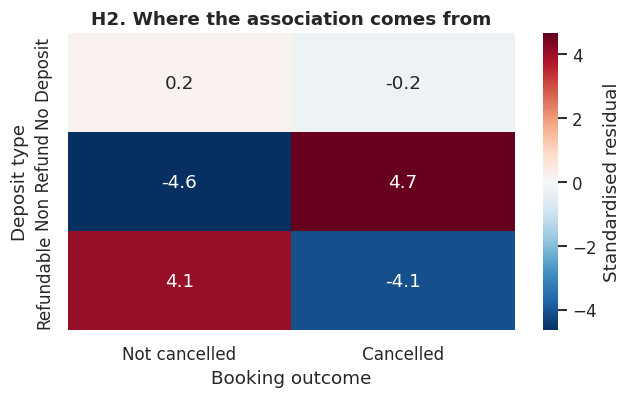

In [31]:
ct = pd.crosstab(df["deposit_type"], df["is_canceled"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
V = cramers_v(ct)
print("Observed counts:"); display(ct)
print(f"Smallest expected count = {exp.min():.1f}  (rule: >= 5)")
print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {p:.3e}, Cramer's V = {V:.3f}")
record("H2", "Cancellation depends on deposit type", "Chi-square", chi2, p, "Cramer V", V)
resid = pd.DataFrame((ct.values - exp) / np.sqrt(exp), index=ct.index, columns=["Not cancelled", "Cancelled"])
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Standardised residual"})
ax.set_title("H2. Where the association comes from"); ax.set_xlabel("Booking outcome"); ax.set_ylabel("Deposit type")
plt.tight_layout(); plt.show()

**Decision: reject H0** (chi-square = 76.6, df = 2, p = 2.4e-17, Cramer's V = 0.118). Cancellation and deposit type are associated. All expected counts are above 5 (smallest 20.5), so the chi-square test is valid.

**Effect size:** V = 0.12 is small *overall* because 98% of bookings share the same deposit type, but the residual heatmap shows a very strong pattern in the small groups: non-refundable bookings cancel far more than expected and refundable bookings far less. Given the very small group sizes and the counter-intuitive direction (Q6), this should be verified with the hotel's records.

### H3 - Is cancellation associated with the market segment? (Q5)
- **H0:** cancellation is independent of market segment.  **H1:** they are associated.
- **Test choice:** chi-square test of independence, followed by a focused two-proportion test for the largest segment (Online TA vs all others).

Smallest expected count = 7.5
chi-square = 410.77, dof = 5, p = 1.414e-86, Cramer's V = 0.274
Focused test - Online TA 62.2% vs other segments 35.6%: difference = +26.6%, 95% CI (+24.0%, +29.1%), z = 19.61, p = 1.20e-85, risk ratio = 1.75


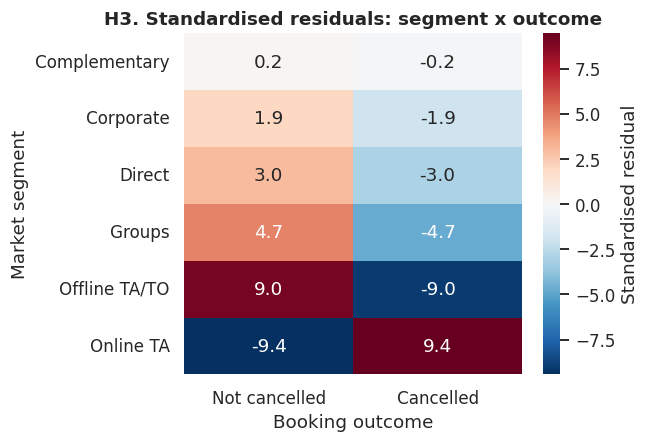

In [32]:
ct = pd.crosstab(df["market_segment"], df["is_canceled"])
chi2, p, dof, exp = stats.chi2_contingency(ct); V = cramers_v(ct)
print(f"Smallest expected count = {exp.min():.1f}")
print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {p:.3e}, Cramer's V = {V:.3f}")
record("H3", "Cancellation depends on market segment", "Chi-square", chi2, p, "Cramer V", V)
ota = df["market_segment"] == "Online TA"
r = two_prop(df.loc[ota, "is_canceled"].sum(), ota.sum(), df.loc[~ota, "is_canceled"].sum(), (~ota).sum())
print(f"Focused test - Online TA {r['p1']:.1%} vs other segments {r['p2']:.1%}: difference = {r['diff']:+.1%}, "
      f"95% CI ({r['ci'][0]:+.1%}, {r['ci'][1]:+.1%}), z = {r['z']:.2f}, p = {r['p']:.2e}, risk ratio = {r['rr']:.2f}")
resid = pd.DataFrame((ct.values - exp) / np.sqrt(exp), index=ct.index, columns=["Not cancelled", "Cancelled"])
fig, ax = plt.subplots(figsize=(6, 4.2))
sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Standardised residual"})
ax.set_title("H3. Standardised residuals: segment x outcome"); ax.set_xlabel("Booking outcome"); ax.set_ylabel("Market segment")
plt.tight_layout(); plt.show()

**Decision: reject H0** (chi-square = 410.8, df = 5, p = 1.4e-86, Cramer's V = 0.274, a moderate association). The smallest expected count is 7.5, so the test is valid.

**Focused test:** Online TA bookings cancel **62.2%** against **35.6%** for all other segments: a difference of **+26.6 percentage points** (95% CI +24.0 to +29.1), risk ratio **1.75**. The residual heatmap shows Online TA with more cancellations than expected and Offline TA/TO, Groups and Corporate with fewer. **Market segment is one of the strongest, practically meaningful drivers of cancellation.**

### H4 - Did the cancellation rate change between 2015 and 2016? (Q2)
- **H0:** p(2015) = p(2016).  **H1:** p(2015) != p(2016).
- **Test choice:** two independent proportions -> **two-proportion z-test** with a 95% confidence interval for the difference. This also checks whether pooling both years is safe.

In [33]:
y15, y16 = df[df["arrival_date_year"] == 2015], df[df["arrival_date_year"] == 2016]
r = two_prop(y15["is_canceled"].sum(), len(y15), y16["is_canceled"].sum(), len(y16))
print(f"2015: {r['p1']:.1%} (n={len(y15):,})   2016: {r['p2']:.1%} (n={len(y16):,})")
print(f"Difference = {r['diff']:+.1%}, 95% CI ({r['ci'][0]:+.1%}, {r['ci'][1]:+.1%}), z = {r['z']:.2f}, p = {r['p']:.2e}")
record("H4", "Cancellation rate differs 2015 vs 2016", "Two-proportion z", r["z"], r["p"], "Risk diff", r["diff"])
# is the jump present inside every segment? (guards against a simple mix-effect explanation)
seg = df.groupby(["market_segment", "arrival_date_year"])["is_canceled"].mean().unstack() * 100
print("Cancellation rate (%) by market segment and year:"); display(seg.round(1))
cty = df.groupby(["country_grp", "arrival_date_year"])["is_canceled"].agg(["mean", "size"]).unstack()
cty.columns = [f"{a}_{b}" for a, b in cty.columns]
print("Cancellation rate and number of bookings by guest origin and year:"); display(cty.round(3))

2015: 32.8% (n=3,122)   2016: 72.5% (n=2,359)
Difference = -39.7%, 95% CI (-42.1%, -37.2%), z = -29.10, p = 3.90e-186
Cancellation rate (%) by market segment and year:
Cancellation rate and number of bookings by guest origin and year:


arrival_date_year,2015,2016
market_segment,,
Complementary,0.000,87.500
Corporate,25.900,87.500
Direct,26.900,83.000
Groups,31.100,35.900
Offline TA/TO,20.900,46.100
Online TA,40.600,88.600


,mean_2015,mean_2016,size_2015,size_2016
country_grp,,,,
International,0.007,0.368,1288,883
Portugal,0.553,0.938,1834,1476


**Decision: reject H0** (z = -29.1, p < 1e-180). The cancellation rate rose from 32.8% to 72.5%, a difference of **+39.7 percentage points** (95% CI 37.2 to 42.1) in 2016.

**What the extra tables show:** the jump is not caused by a change in the mix of channels or origins. It appears inside **almost every segment** (e.g. Online TA 41% -> 89%, Direct 27% -> 83%, Offline TA/TO 21% -> 46%) and for **both guest origins** (Portugal 55% -> 94%, international 0.7% -> 37%). International guests almost never cancelled in 2015 (0.7%), which is unusual for hotel data.

**Conclusion:** the two years are not homogeneous, so a single pooled cancellation rate is misleading. The most plausible explanations are a change in how cancellations were recorded or in the property's booking policies; it cannot be settled from this file. This is why the year is excluded from the model and an out-of-time check is added.

### H5 - A/B test: do bookings with special requests cancel less often? (Q8)
- **Group A (control):** no special request.  **Group B (treatment-like):** at least one special request.
- **H0:** p(B) >= p(A).  **H1:** p(B) < p(A) (one-sided, because the business expectation is that engaged guests cancel less).
- **Test choice:** one-sided two-proportion z-test; effect reported as risk difference, risk ratio and a confidence interval.

A (no request): 53.1% cancelled, n = 2,975
B (>=1 request): 46.0% cancelled, n = 2,506
Difference B - A = -7.1%, 95% CI (-9.8%, -4.5%); risk ratio = 0.87
z = -5.26, one-sided p = 7.14e-08


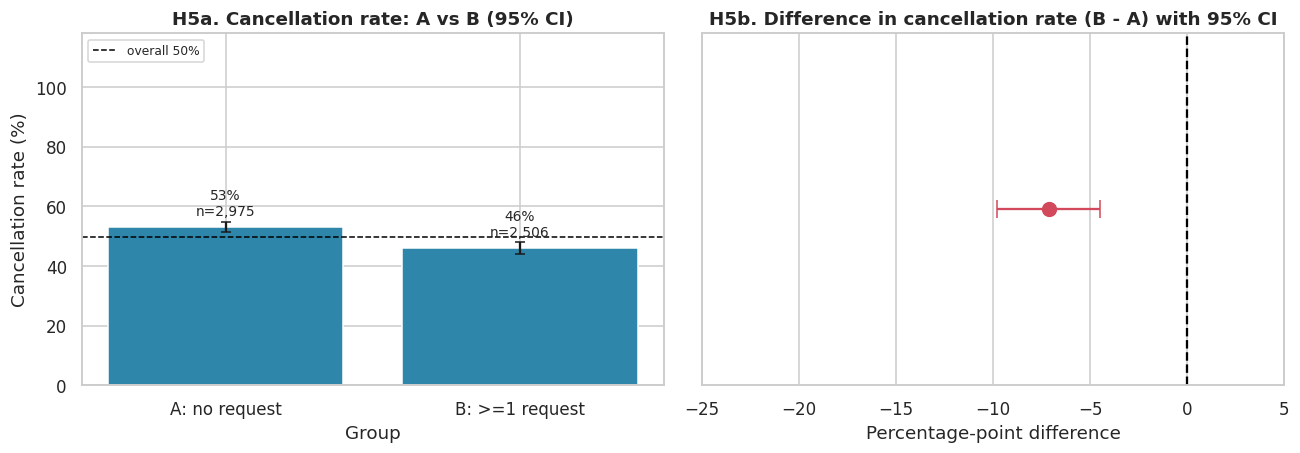

In [34]:
A = df[df["has_request"] == 0]; B = df[df["has_request"] == 1]
r = two_prop(B["is_canceled"].sum(), len(B), A["is_canceled"].sum(), len(A), alt="less")
print(f"A (no request): {r['p2']:.1%} cancelled, n = {len(A):,}")
print(f"B (>=1 request): {r['p1']:.1%} cancelled, n = {len(B):,}")
print(f"Difference B - A = {r['diff']:+.1%}, 95% CI ({r['ci'][0]:+.1%}, {r['ci'][1]:+.1%}); risk ratio = {r['rr']:.2f}")
print(f"z = {r['z']:.2f}, one-sided p = {r['p']:.2e}")
record("H5", "Special requests reduce cancellation (A/B)", "Two-proportion z (1-sided)", r["z"], r["p"], "Risk diff", r["diff"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
gA = rate_table(df.assign(grp=np.where(df["has_request"] == 1, "B: >=1 request", "A: no request")), "grp")
plot_rate(axes[0], gA, "H5a. Cancellation rate: A vs B (95% CI)", "Group")
axes[1].errorbar([r["diff"] * 100], [0], xerr=[[r["diff"] * 100 - r["ci"][0] * 100], [r["ci"][1] * 100 - r["diff"] * 100]],
                 fmt="o", color=RED, capsize=6, markersize=9)
axes[1].axvline(0, color="black", ls="--"); axes[1].set_yticks([])
axes[1].set_title("H5b. Difference in cancellation rate (B - A) with 95% CI")
axes[1].set_xlabel("Percentage-point difference"); axes[1].set_xlim(-25, 5)
plt.tight_layout(); plt.show()

**Decision: reject H0** (z = -5.26, one-sided p = 7.1e-8). Bookings with at least one special request cancelled **46.0%** of the time against **53.1%** for bookings with none: **7.1 percentage points lower** (95% CI -9.8 to -4.5; risk ratio 0.87, a **13% relative reduction**).

**Justification and caution:** the confidence interval is entirely below zero, so the effect is both statistically significant and reasonably large. As noted at the start of this section, the groups were not randomly assigned: guests who make requests may simply be more committed travellers. So this supports the *association*, and a real A/B experiment (for example, proactively inviting guests to state preferences) would be needed to prove that engagement *causes* fewer cancellations.

### H6 - Does the average price (ADR) differ across customer types? (Q7)
- **H0:** all customer types have the same mean ADR.  **H1:** at least one differs.
- **Test choice:** more than two groups, numeric outcome -> **one-way ANOVA**; because ADR is skewed and group sizes are unequal, the **Kruskal-Wallis** test is run as a robustness check, followed by **Tukey HSD** post-hoc comparisons.

Group sizes: {'Contract': 268, 'Group': 10, 'Transient': 4370, 'Transient-Party': 700}
Levene (equal variances): p = 0.0000
ANOVA: F = 98.91, p = 2.638e-62, eta-squared = 0.053
Kruskal-Wallis: H = 291.30, p = 7.577e-63


,Pair,Mean diff,Tukey p
0,Contract vs Group,-21.643,0.544
1,Contract vs Transient,-29.957,0.000
2,Contract vs Transient-Party,1.337,0.983
3,Group vs Transient,-8.314,0.954
4,Group vs Transient-Party,22.980,0.482
5,Transient vs Transient-Party,31.295,0.000


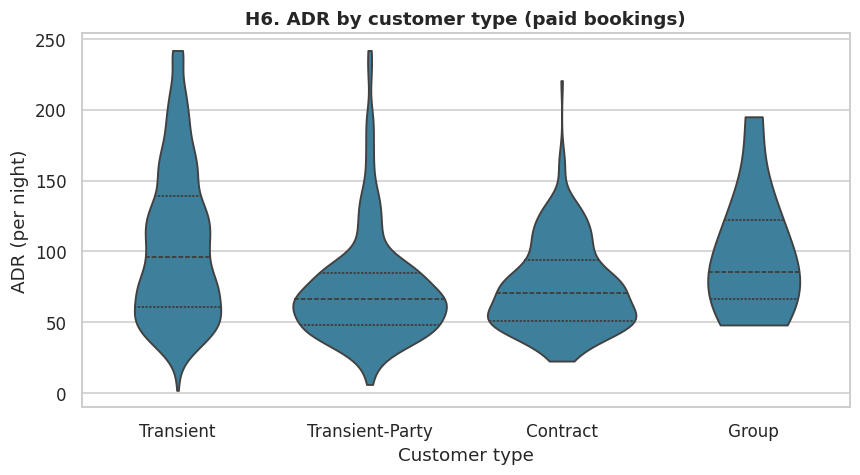

In [35]:
groups = {k: v["adr"].values for k, v in paid.groupby("customer_type")}
print("Group sizes:", {k: len(v) for k, v in groups.items()})
print(f"Levene (equal variances): p = {stats.levene(*groups.values()).pvalue:.4f}")
f = stats.f_oneway(*groups.values()); kw = stats.kruskal(*groups.values())
allv = np.concatenate(list(groups.values()))
eta2 = sum(len(v) * (v.mean() - allv.mean()) ** 2 for v in groups.values()) / ((allv - allv.mean()) ** 2).sum()
print(f"ANOVA: F = {f.statistic:.2f}, p = {f.pvalue:.3e}, eta-squared = {eta2:.3f}")
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.3e}")
record("H6", "ADR differs by customer type", "One-way ANOVA", f.statistic, f.pvalue, "eta-squared", eta2)
names = list(groups.keys()); tk = stats.tukey_hsd(*groups.values())
rows = [{"Pair": f"{names[i]} vs {names[j]}", "Mean diff": groups[names[i]].mean() - groups[names[j]].mean(),
         "Tukey p": tk.pvalue[i][j]} for i in range(len(names)) for j in range(i + 1, len(names))]
display(pd.DataFrame(rows))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=paid, x="customer_type", y="adr", order=order, color=BLUE, inner="quartile", cut=0, ax=ax)
ax.set_title("H6. ADR by customer type (paid bookings)"); ax.set_xlabel("Customer type"); ax.set_ylabel("ADR (per night)")
plt.tight_layout(); plt.show()

**Decision: reject H0** (ANOVA F = 98.9, p = 2.6e-62; Kruskal-Wallis H = 291.3, p = 7.6e-63). Mean ADR differs by customer type. Because the variances are unequal (Levene p < 0.001) and the groups are very different in size, the non-parametric Kruskal-Wallis result is shown as a check and agrees with ANOVA.

**Effect size and post-hoc:** eta-squared = 0.053, so customer type explains about 5% of the variation in price (a small-to-medium effect). Tukey HSD shows the difference comes from **Transient guests paying about 30 more per night** than Transient-Party (p < 0.001) and Contract (p < 0.001) guests; the other pairs are not significant. The Group type has only 10 paid bookings, so it cannot support a conclusion.

### H7 - Is the price higher in summer than in the rest of the year? (Q9)
- **H0:** mean ADR (summer) <= mean ADR (other seasons).  **H1:** summer ADR is higher (one-sided).
- **Test choice:** Welch t-test (unequal variances) with a Mann-Whitney check.

Mean ADR: summer = 139.9 (n=2,268), other seasons = 69.5 (n=3,080), difference = 70.4
Welch t = 62.08, one-sided p = 0.00e+00, Cohen's d = 1.77;  Mann-Whitney p = 0.00e+00


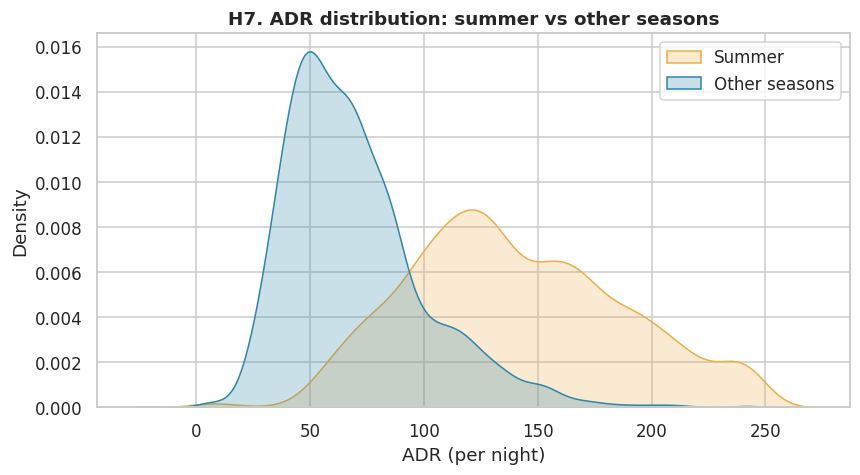

In [36]:
s_ = paid.loc[paid["season"] == "Summer", "adr"]; o_ = paid.loc[paid["season"] != "Summer", "adr"]
t = stats.ttest_ind(s_, o_, equal_var=False, alternative="greater")
u = stats.mannwhitneyu(s_, o_, alternative="greater"); d = cohens_d(s_, o_)
print(f"Mean ADR: summer = {s_.mean():.1f} (n={len(s_):,}), other seasons = {o_.mean():.1f} (n={len(o_):,}), difference = {s_.mean()-o_.mean():.1f}")
print(f"Welch t = {t.statistic:.2f}, one-sided p = {t.pvalue:.2e}, Cohen's d = {d:.2f};  Mann-Whitney p = {u.pvalue:.2e}")
record("H7", "ADR higher in summer", "Welch t (1-sided)", t.statistic, t.pvalue, "Cohen d", d)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.kdeplot(s_, fill=True, color=ORANGE, label="Summer", ax=ax); sns.kdeplot(o_, fill=True, color=BLUE, label="Other seasons", ax=ax)
ax.set_title("H7. ADR distribution: summer vs other seasons"); ax.set_xlabel("ADR (per night)"); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout(); plt.show()

**Decision: reject H0** (Welch t = 62.1, one-sided p < 1e-300; Mann-Whitney agrees). Summer ADR averages **139.9** against **69.5** for the rest of the year, a difference of **70.4 per night (about +100%)** and a huge effect (Cohen's d = 1.77).

**Justification:** the effect is so large that the exact p-value is almost irrelevant: the two price distributions barely overlap (density plot). The same caution as in Q9 applies: the summer months come from both years, so some of the gap also reflects price growth over time.

### H8 - Do bookings with children pay a different price? (Q15)
- **H0:** mean ADR is equal for bookings with and without children.  **H1:** the means differ.
- **Test choice:** Welch t-test with a Mann-Whitney check.

In [37]:
w = fam_paid.loc[fam_paid["has_children"] == 1, "adr"]; wo = fam_paid.loc[fam_paid["has_children"] == 0, "adr"]
t = stats.ttest_ind(w, wo, equal_var=False); u = stats.mannwhitneyu(w, wo); d = cohens_d(w, wo)
print(f"Mean ADR: with children = {w.mean():.1f} (n={len(w):,}), without = {wo.mean():.1f} (n={len(wo):,})")
print(f"Welch t = {t.statistic:.2f}, p = {t.pvalue:.2e}, Cohen's d = {d:.2f};  Mann-Whitney p = {u.pvalue:.2e}")
record("H8", "ADR differs with children", "Welch t-test", t.statistic, t.pvalue, "Cohen d", d)

Mean ADR: with children = 145.3 (n=649), without = 93.1 (n=4,699)
Welch t = 22.27, p = 2.04e-85, Cohen's d = 0.99;  Mann-Whitney p = 2.93e-102


**Decision: reject H0** (Welch t = 22.3, p = 2.0e-85; Mann-Whitney agrees). Bookings with children pay **145.3** per night against **93.1** without, **+52 per night (about +56%)**, a large effect (Cohen's d = 0.99).

**Justification:** families appear to book larger or higher-category rooms or travel at higher-priced times; the data cannot say which. Either way they are a high-revenue-per-night segment.

### H9 - Do domestic (Portuguese) and international guests cancel at different rates? (Q13)
- **H0:** p(Portugal) = p(International).  **H1:** the rates differ.
- **Test choice:** two-proportion z-test. Because the year effect (H4) could distort this comparison, the difference is also checked **within each year**.

Portugal 72.5% (n=3,310) vs International 15.4% (n=2,171): difference = +57.1%, 95% CI (+55.0%, +59.3%), z = 41.4, p = 0.00e+00, risk ratio = 4.71
  Within 2015: Portugal 55.3% vs International 0.7% (difference +54.6%, p = 6.5e-225)
  Within 2016: Portugal 93.8% vs International 36.8% (difference +57.0%, p = 6.0e-198)


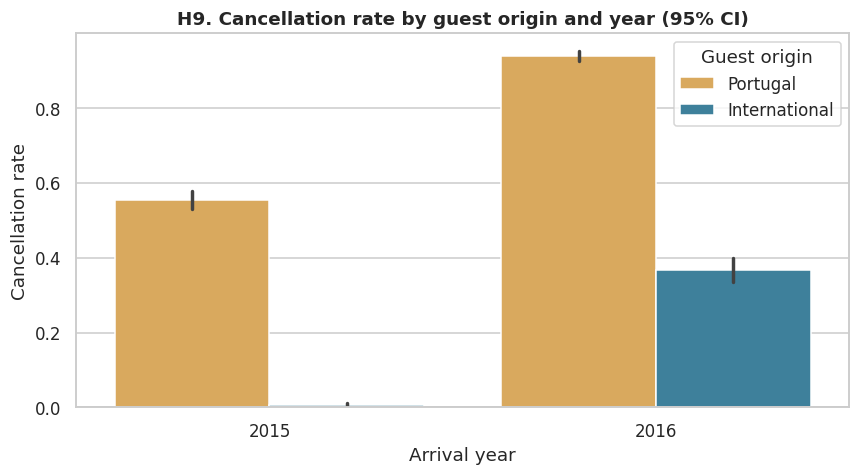

In [38]:
dom = df["country_grp"] == "Portugal"
r = two_prop(df.loc[dom, "is_canceled"].sum(), dom.sum(), df.loc[~dom, "is_canceled"].sum(), (~dom).sum())
print(f"Portugal {r['p1']:.1%} (n={dom.sum():,}) vs International {r['p2']:.1%} (n={(~dom).sum():,}): difference = {r['diff']:+.1%}, "
      f"95% CI ({r['ci'][0]:+.1%}, {r['ci'][1]:+.1%}), z = {r['z']:.1f}, p = {r['p']:.2e}, risk ratio = {r['rr']:.2f}")
record("H9", "Cancellation differs Portugal vs International", "Two-proportion z", r["z"], r["p"], "Risk diff", r["diff"])
for yr in [2015, 2016]:
    sub = df[df["arrival_date_year"] == yr]; d_ = sub["country_grp"] == "Portugal"
    ry = two_prop(sub.loc[d_, "is_canceled"].sum(), d_.sum(), sub.loc[~d_, "is_canceled"].sum(), (~d_).sum())
    print(f"  Within {yr}: Portugal {ry['p1']:.1%} vs International {ry['p2']:.1%} (difference {ry['diff']:+.1%}, p = {ry['p']:.1e})")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df, x="arrival_date_year", y="is_canceled", hue="country_grp", palette=[ORANGE, BLUE], errorbar=("ci", 95), ax=ax)
ax.set_title("H9. Cancellation rate by guest origin and year (95% CI)"); ax.set_xlabel("Arrival year"); ax.set_ylabel("Cancellation rate")
ax.legend(title="Guest origin"); plt.tight_layout(); plt.show()

**Decision: reject H0** (z = 41.4, p < 1e-300). Portuguese guests cancel **72.5%** of the time against **15.4%** for international guests: a difference of **+57.1 percentage points** (95% CI 55.0 to 59.3), risk ratio **4.7**.

**Check against the year effect:** the gap is present *inside each year* (2015: 55.3% vs 0.7%; 2016: 93.8% vs 36.8%), so it is not simply an artefact of mixing the two years. The size of the difference, however, is exceptionally large and should be confirmed on the complete dataset.

### Summary of all hypothesis tests (with Holm correction)

In [39]:
res = pd.DataFrame(results)
p = res["p-value"].values; order_ = np.argsort(p); m_ = len(p)
adj = np.empty(m_); running = 0
for rank, idx in enumerate(order_):
    running = max(running, (m_ - rank) * p[idx]); adj[idx] = min(1, running)
res["Holm-adjusted p"] = adj
res["Decision (alpha = 0.05)"] = np.where(res["Holm-adjusted p"] < ALPHA, "Reject H0", "Fail to reject H0")
res["p-value"] = res["p-value"].map(lambda v: "<1e-300" if v < 1e-300 else (f"{v:.2e}" if v < 0.001 else f"{v:.4f}"))
res["Holm-adjusted p"] = res["Holm-adjusted p"].map(lambda v: "<1e-300" if v < 1e-300 else (f"{v:.2e}" if v < 0.001 else f"{v:.4f}"))
res["Statistic"] = res["Statistic"].round(2)
display(res)

,ID,Question,Test,Statistic,p-value,Effect size,Holm-adjusted p,Decision (alpha = 0.05)
0,H1,Lead time differs by cancellation,Welch t-test,-0.210,0.8349,Cohen d = -0.006,0.8349,Fail to reject H0
1,H2,Cancellation depends on deposit type,Chi-square,76.560,2.37e-17,Cramer V = 0.118,7.10e-17,Reject H0
2,H3,Cancellation depends on market segment,Chi-square,410.770,1.41e-86,Cramer V = 0.274,8.48e-86,Reject H0
3,H4,Cancellation rate differs 2015 vs 2016,Two-proportion z,-29.100,3.90e-186,Risk diff = -0.397,2.73e-185,Reject H0
4,H5,Special requests reduce cancellation (A/B),Two-proportion z (1-sided),-5.260,7.14e-08,Risk diff = -0.071,1.43e-07,Reject H0
5,H6,ADR differs by customer type,One-way ANOVA,98.910,2.64e-62,eta-squared = 0.053,1.06e-61,Reject H0
6,H7,ADR higher in summer,Welch t (1-sided),62.080,<1e-300,Cohen d = 1.769,<1e-300,Reject H0
7,H8,ADR differs with children,Welch t-test,22.270,2.04e-85,Cohen d = 0.992,1.02e-84,Reject H0
8,H9,Cancellation differs Portugal vs International,Two-proportion z,41.370,<1e-300,Risk diff = 0.571,<1e-300,Reject H0


### Decision drawn from the analysis and the evidence behind it

| # | Decision for the hotel | Evidence |
|---|---|---|
| 1 | **Treat Online TA bookings as the main cancellation risk** and apply tighter terms (reconfirmation, partial deposit, overbooking buffer) to them | 62% vs 36% cancellation; two-thirds of all cancellations; H3: chi-square p = 1e-86, risk ratio 1.75 |
| 2 | **Treat domestic (Portuguese) bookings as high-risk** when forecasting occupancy | 72.5% vs 15.4%; H9: risk ratio 4.7 in both years |
| 3 | **Do not use lead time alone** to flag risky bookings | H1: means equal (p = 0.83); Q4: the relationship is inverted-U, not linear |
| 4 | **Encourage guests to state special requests** (pre-arrival email/form) as an engagement tool, and test it with a real A/B experiment | H5: 7.1 points lower cancellation, p = 7e-8, but not randomised |
| 5 | **Review the deposit policy and its data labelling** before changing it | H2: association is significant but direction is counter-intuitive and the groups are tiny (81 and 41 bookings) |
| 6 | **Use dynamic pricing**: peak summer pricing and a family package are justified | H7: summer ADR about twice the rest of the year (d = 1.77); H8: families pay 56% more per night (d = 0.99) |
| 7 | **Do not pool the two years blindly**; monitor the cancellation rate over time and retrain any model regularly | H4: 32.8% -> 72.5%, p < 1e-180, in almost every segment |

After the Holm correction for nine tests, **eight of the nine null hypotheses are rejected**; only H1 (lead time) is not.

## 7. Machine-Learning Model: Predicting Cancellation (Classification)

**Technique chosen: logistic regression (classification).**

**Why this technique?**
- The target `is_canceled` is binary, so this is a classification problem.
- It builds directly on the analysis: the statistical tests showed which variables matter, and logistic regression turns them into a probability for each booking.
- It is **interpretable**: each coefficient converts into an *odds ratio* that a revenue manager can read ("non-refundable bookings have X times the odds of cancelling").
- It is a sound baseline for a dataset of this size (about 5,500 rows) and gives well-behaved probabilities, which are needed for risk bands in Tableau.

**Features used:** only information known at booking time. The leakage columns `reservation_status` and `reservation_status_date` were removed in preprocessing. Arrival year and month are *not* used (the year effect found in H4 would let the model learn a data artefact rather than booking behaviour).

In [40]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import calibration_curve

class Winsorizer(BaseEstimator, TransformerMixin):
    """Cap each numeric column at the 99th percentile learned on the TRAINING data only (no leakage)."""
    def fit(self, X, y=None):
        self.caps_ = np.nanpercentile(np.asarray(X, dtype=float), 99, axis=0); return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.caps_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

num_feats = ["lead_time", "total_nights", "total_guests", "adr", "booking_changes", "total_of_special_requests",
             "required_car_parking_spaces"]
bin_feats = ["has_children"]
cat_feats = ["deposit_type", "market_segment", "customer_type", "meal", "country_grp"]
X, y = df[num_feats + bin_feats + cat_feats], df["is_canceled"]

def make_model():
    """A fresh (unfitted) pipeline every time, so that bootstrap / CV fits never overwrite the main model."""
    pre = ColumnTransformer([
        ("num", Pipeline([("cap", Winsorizer()), ("scale", StandardScaler())]), num_feats),
        ("bin", "passthrough", bin_feats),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_feats),
    ])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

model = make_model()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_tr):,} rows   Test: {len(X_te):,} rows   (cancellation rate train {y_tr.mean():.1%}, test {y_te.mean():.1%})")
model.fit(X_tr, y_tr)

Train: 4,384 rows   Test: 1,097 rows   (cancellation rate train 49.9%, test 49.9%)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('cap',
                                                                   Winsorizer()),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['lead_time', 'total_nights',
                                                   'total_guests', 'adr',
                                                   'booking_changes',
                                                   'total_of_special_requests',
                                                   'required_car_parking_spaces']),
                                                 ('bin', 'passthrough',
                                                  ['has_children']),
                                                 ('cat',
            

**Methodology.** 80/20 stratified train-test split; numeric features are capped at the 99th percentile and standardised, categorical features are one-hot encoded (first level dropped to avoid the dummy-variable trap). A majority-class model is used as the baseline to show that the model learns something real.

In [41]:
# ---- assumption checks
print("Assumption 1 - binary outcome, independent observations: duplicates were removed in preprocessing.")
print(f"Assumption 2 - enough events per predictor: {int(y.sum())} cancellations for about {X_tr.shape[1]} predictors -> fine.")
Xn = pd.DataFrame(StandardScaler().fit_transform(df[num_feats].clip(upper=df[num_feats].quantile(.99), axis=1)), columns=num_feats)
vif = {col: 1 / (1 - LinearRegression().fit(Xn.drop(columns=col), Xn[col]).score(Xn.drop(columns=col), Xn[col])) for col in num_feats}
print("Assumption 3 - no severe multicollinearity. Variance inflation factors (VIF < 5 is acceptable):")
display(pd.Series(vif).round(2).to_frame("VIF"))

Assumption 1 - binary outcome, independent observations: duplicates were removed in preprocessing.
Assumption 2 - enough events per predictor: 2734 cancellations for about 13 predictors -> fine.
Assumption 3 - no severe multicollinearity. Variance inflation factors (VIF < 5 is acceptable):


,VIF
lead_time,1.230
total_nights,1.190
total_guests,1.210
adr,1.250
booking_changes,1.020
total_of_special_requests,1.010
required_car_parking_spaces,1.030


5-fold cross-validation: ROC-AUC = 0.905 +/- 0.009,  accuracy = 0.831 +/- 0.017


,Accuracy,Precision,Recall,F1,ROC-AUC,Brier score
Model,,,,,,
Baseline (majority class),0.501,0.000,0.000,0.000,0.500,0.499
Logistic regression,0.843,0.835,0.854,0.844,0.921,0.109


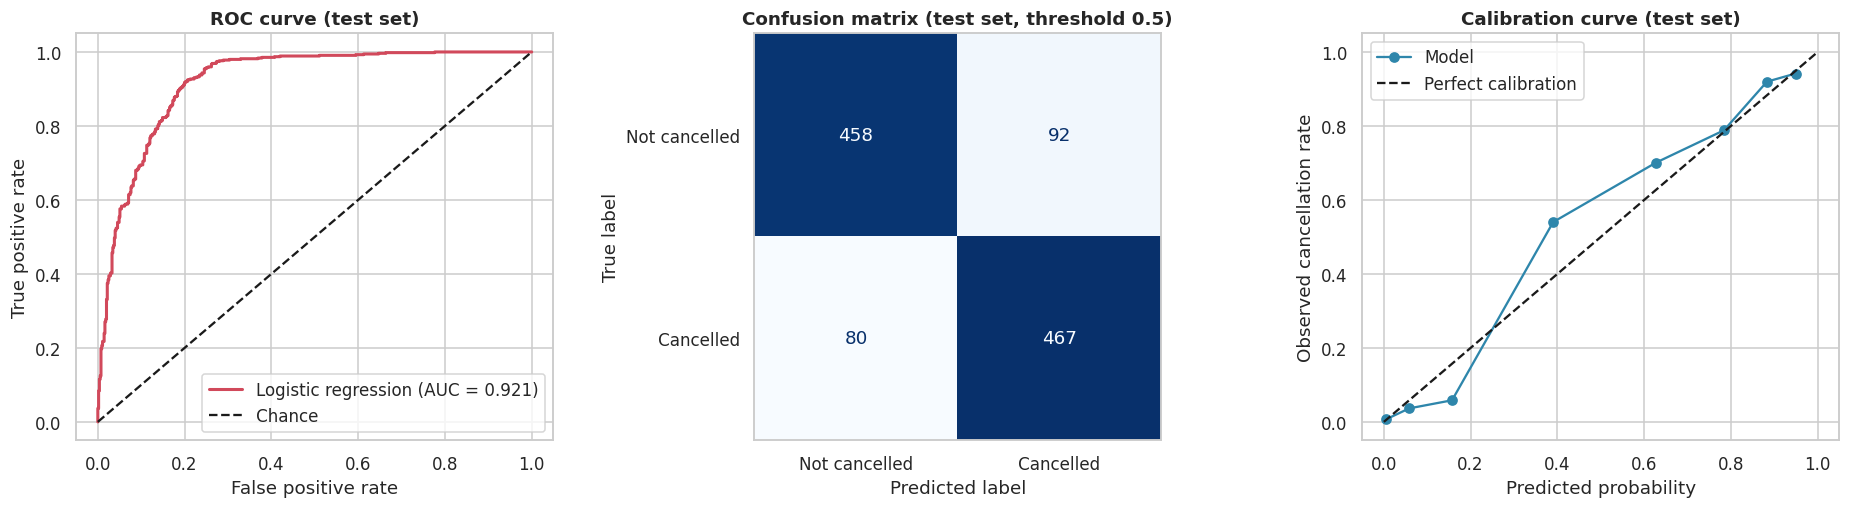

In [42]:
# ---- evaluation
baseline = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
def evaluate(clf, name):
    pred = clf.predict(X_te); prob = clf.predict_proba(X_te)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, prob),
            "Brier score": brier_score_loss(y_te, prob)}
metrics = pd.DataFrame([evaluate(baseline, "Baseline (majority class)"), evaluate(model, "Logistic regression")]).set_index("Model")
display(metrics)

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc"); cv_acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print(f"5-fold cross-validation: ROC-AUC = {cv_auc.mean():.3f} +/- {cv_auc.std():.3f},  accuracy = {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}")

prob_te = model.predict_proba(X_te)[:, 1]
fpr, tpr, _ = roc_curve(y_te, prob_te)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(fpr, tpr, color=RED, lw=2, label=f"Logistic regression (AUC = {roc_auc_score(y_te, prob_te):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance"); axes[0].set_title("ROC curve (test set)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(loc="lower right")
ConfusionMatrixDisplay(confusion_matrix(y_te, model.predict(X_te)), display_labels=["Not cancelled", "Cancelled"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix (test set, threshold 0.5)"); axes[1].grid(False)
fp, mp = calibration_curve(y_te, prob_te, n_bins=8, strategy="quantile")
axes[2].plot(mp, fp, marker="o", color=BLUE, label="Model"); axes[2].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[2].set_title("Calibration curve (test set)"); axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed cancellation rate"); axes[2].legend()
plt.tight_layout(); plt.show()

**Interpretation of the results**
- **Beats the baseline clearly:** accuracy **84.3%** against 50.1% for always predicting the majority class; precision 83.5%, recall 85.4%, F1 = 0.844, **ROC-AUC = 0.921**, Brier score 0.109 (baseline 0.499).
- **Stable, not a lucky split:** 5-fold cross-validation gives ROC-AUC 0.905 +/- 0.009 and accuracy 83.1% +/- 1.7%.
- **Confusion matrix:** of 547 cancellations in the test set the model catches 467 and misses 80 (14.6%); it raises 92 false alarms among 550 bookings that were kept. A hotel that values avoiding an empty room more than avoiding an unnecessary overbooking can lower the 0.5 threshold to catch more cancellations.
- **Probabilities are trustworthy:** the calibration curve follows the diagonal closely, so a predicted 80% really means about 80%, which is what makes risk bands in Tableau meaningful.
- **Assumptions:** observations are independent (duplicates removed), there are many cancellations per predictor, and multicollinearity is not a problem (every VIF is below 1.3).

,feature,odds_ratio,ci_low,ci_high,significant
22,country_grp_Portugal,25.168,21.204,30.568,True
6,required_car_parking_spaces,0.119,0.107,0.133,True
8,deposit_type_Non Refund,7.398,3.782,16.165,True
9,deposit_type_Refundable,0.200,0.111,0.450,True
21,meal_Undefined,0.317,0.177,0.631,True
14,market_segment_Online TA,2.900,1.856,4.554,True
15,customer_type_Group,2.365,0.982,6.454,False
16,customer_type_Transient,2.116,1.473,2.838,True
18,meal_FB,0.555,0.327,1.116,False
5,total_of_special_requests,0.560,0.503,0.609,True


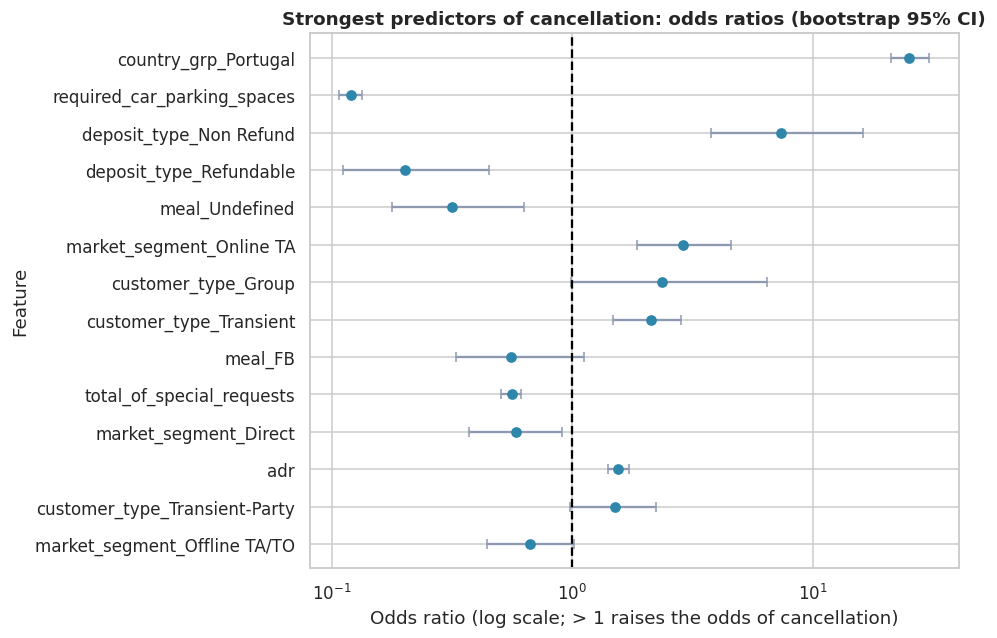

In [43]:
# ---- coefficients -> odds ratios with bootstrap 95% CI
feat_names = model.named_steps["prep"].get_feature_names_out()
feat_names = [n.split("__", 1)[1] for n in feat_names]
coef = model.named_steps["clf"].coef_[0]
rng = np.random.default_rng(RANDOM_STATE); boots = []
for _ in range(300):
    idx = rng.integers(0, len(X_tr), len(X_tr))
    mb = make_model().fit(X_tr.iloc[idx], y_tr.iloc[idx])
    boots.append(mb.named_steps["clf"].coef_[0])
boots = np.array(boots)
orr = pd.DataFrame({"feature": feat_names, "odds_ratio": np.exp(coef),
                    "ci_low": np.exp(np.percentile(boots, 2.5, axis=0)), "ci_high": np.exp(np.percentile(boots, 97.5, axis=0))})
orr["significant"] = (orr["ci_low"] > 1) | (orr["ci_high"] < 1)
orr = orr.reindex(orr["odds_ratio"].apply(np.log).abs().sort_values(ascending=False).index)
display(orr.head(15))
top = orr.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(top["odds_ratio"], range(len(top)), xerr=[top["odds_ratio"] - top["ci_low"], top["ci_high"] - top["odds_ratio"]],
            fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(1, color="black", ls="--"); ax.set_xscale("log"); ax.set_yticks(range(len(top))); ax.set_yticklabels(top["feature"])
ax.set_title("Strongest predictors of cancellation: odds ratios (bootstrap 95% CI)")
ax.set_xlabel("Odds ratio (log scale; > 1 raises the odds of cancellation)"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

**What the model learned (odds ratios; >1 raises the odds of cancellation)**
- Numeric features are standardised, so their odds ratio is *per one standard deviation*. The baseline categories are: country = International, deposit = No Deposit, customer = Contract, meal = BB, segment = Complementary (an alphabetical default), so segment ratios are relative to that small group.
- **Portuguese guests:** OR = **25.2** (95% CI 21.2-30.6): by far the strongest effect, in line with H9.
- **Required parking spaces:** OR = **0.12** per SD (0.11-0.13): guests who plan to arrive by car are very unlikely to cancel.
- **Non-refundable deposit:** OR = 7.4 (3.8-16.2); **refundable:** OR = 0.20 (0.11-0.45).
- **Online TA:** OR = 2.9 against the baseline segment (about five times the odds of Direct, 2.9 / 0.58).
- **Special requests:** OR = 0.56 per SD (0.50-0.61), supporting H5. **Higher ADR:** OR = 1.55 per SD; **children in the booking:** OR = 1.47 (1.03-2.32).
- Odds ratios whose bootstrap interval includes 1 (for example Group customers, Transient-Party, Offline TA/TO) are not reliably different from their baseline.

The model therefore confirms, with all variables considered at once, the same factors found by the separate statistical tests.

,CV ROC-AUC,SD
All features,0.905,0.009
Without country (country_grp),0.792,0.007
Without deposit type,0.902,0.009
Without market segment,0.889,0.008
Without parking & booking changes,0.870,0.013


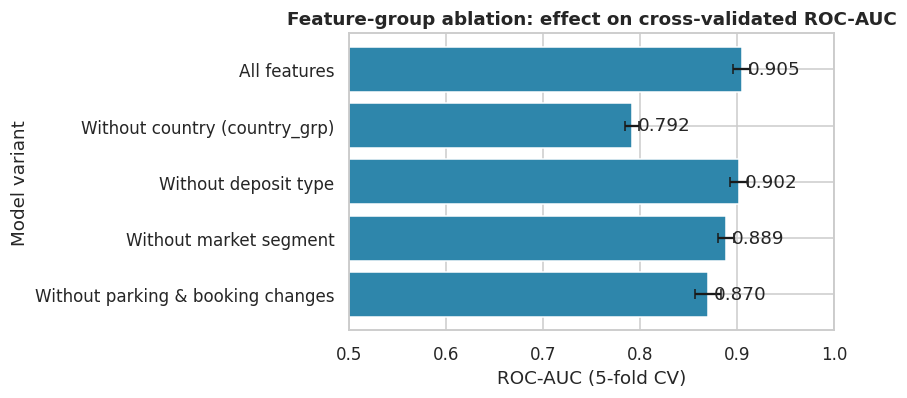

In [44]:
# ---- robustness: how much does each feature group matter? (5-fold CV ROC-AUC)
def cv_auc_for(num, binf, cat):
    pre_ = ColumnTransformer([("num", Pipeline([("cap", Winsorizer()), ("scale", StandardScaler())]), num),
                              ("bin", "passthrough", binf), ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])
    mdl = Pipeline([("prep", pre_), ("clf", LogisticRegression(max_iter=2000))])
    sc = cross_val_score(mdl, df[num + binf + cat], y, cv=cv, scoring="roc_auc"); return sc.mean(), sc.std()
variants = {
    "All features": (num_feats, bin_feats, cat_feats),
    "Without country (country_grp)": (num_feats, bin_feats, [c_ for c_ in cat_feats if c_ != "country_grp"]),
    "Without deposit type": (num_feats, bin_feats, [c_ for c_ in cat_feats if c_ != "deposit_type"]),
    "Without market segment": (num_feats, bin_feats, [c_ for c_ in cat_feats if c_ != "market_segment"]),
    "Without parking & booking changes": ([f_ for f_ in num_feats if f_ not in ("required_car_parking_spaces", "booking_changes")], bin_feats, cat_feats),
}
abl = pd.DataFrame({k: cv_auc_for(*v) for k, v in variants.items()}, index=["CV ROC-AUC", "SD"]).T
display(abl)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(abl.index[::-1], abl["CV ROC-AUC"].values[::-1], xerr=abl["SD"].values[::-1], color=BLUE, capsize=3)
for i, v in enumerate(abl["CV ROC-AUC"].values[::-1]): ax.text(v + 0.006, i, f"{v:.3f}", va="center")
ax.set_xlim(0.5, 1.0); ax.set_title("Feature-group ablation: effect on cross-validated ROC-AUC")
ax.set_xlabel("ROC-AUC (5-fold CV)"); ax.set_ylabel("Model variant")
plt.tight_layout(); plt.show()

**Interpretation:** removing groups of features shows what the model depends on. Without **country** the cross-validated ROC-AUC falls from 0.905 to **0.792**, so country is the single most important predictor. Removing market segment lowers it to 0.889, parking and booking changes to 0.870, and deposit type hardly matters (0.902, because only 122 bookings have a deposit). The model still performs well above chance (0.5) without country, so it is not relying on one feature alone, but it is clear that its accuracy is tied to a country effect that should be re-checked on the full dataset.

In [45]:
# ---- out-of-time validation: train on the earlier arrivals, test on the later ones
cut = pd.Timestamp("2016-03-01")
tr, te = df["arrival_date"] < cut, df["arrival_date"] >= cut
m_oot = make_model().fit(X[tr], y[tr])
p_oot = m_oot.predict_proba(X[te])[:, 1]
print(f"Train: arrivals before {cut.date()} (n={tr.sum():,}, cancel rate {y[tr].mean():.1%})")
print(f"Test : arrivals from   {cut.date()} (n={te.sum():,}, cancel rate {y[te].mean():.1%})")
print(f"Out-of-time ROC-AUC = {roc_auc_score(y[te], p_oot):.3f},  accuracy = {accuracy_score(y[te], p_oot > .5):.3f}  "
      f"(majority-class accuracy = {max(y[te].mean(), 1 - y[te].mean()):.3f})")
print(f"Mean predicted probability = {p_oot.mean():.3f} vs observed rate = {y[te].mean():.3f}")

Train: arrivals before 2016-03-01 (n=3,407, cancel rate 36.3%)
Test : arrivals from   2016-03-01 (n=2,074, cancel rate 72.2%)
Out-of-time ROC-AUC = 0.874,  accuracy = 0.760  (majority-class accuracy = 0.722)
Mean predicted probability = 0.453 vs observed rate = 0.722


**Interpretation (a stricter, more realistic test):** the model is trained on arrivals before March 2016 and tested on the later arrivals. Its **ranking ability holds up (ROC-AUC 0.874)** - it still puts the riskiest bookings first - but accuracy (76.0%) is only a little above simply predicting "cancelled" for everyone (72.2%), and the average predicted probability (45%) is far below the actual rate (72%). The reason is the doubling of the cancellation rate discovered in Q2/H4: the model learned the 2015 level of risk.

**Practical lesson:** use the model to **rank** bookings by risk, and retrain it (or recalibrate its threshold) regularly on recent data, because cancellation behaviour in this property changed over time.

,bookings,actual_cancel_rate,revenue_at_stake
risk_band,,,
Low,2134,0.066,"943,932.960"
Medium,989,0.615,"429,570.785"
High,2358,0.842,"1,309,916.095"


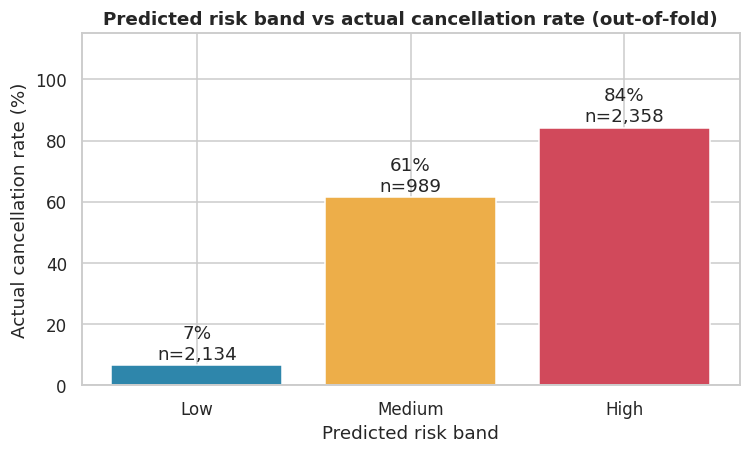

In [46]:
# ---- out-of-fold risk scores for every booking (used by the Tableau dashboard)
oof = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
df["pred_cancel_prob"] = oof
df["risk_band"] = pd.cut(df["pred_cancel_prob"], bins=[-0.01, 0.33, 0.66, 1.0], labels=["Low", "Medium", "High"])
band = df.groupby("risk_band", observed=True).agg(bookings=("is_canceled", "size"), actual_cancel_rate=("is_canceled", "mean"),
                                                  revenue_at_stake=("revenue_at_stake", "sum"))
display(band)
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.bar(band.index.astype(str), band["actual_cancel_rate"] * 100, color=[BLUE, ORANGE, RED])
for i, (r, n) in enumerate(zip(band["actual_cancel_rate"], band["bookings"])): ax.text(i, r * 100 + 2, f"{r:.0%}\nn={n:,}", ha="center")
ax.set_title("Predicted risk band vs actual cancellation rate (out-of-fold)"); ax.set_xlabel("Predicted risk band"); ax.set_ylabel("Actual cancellation rate (%)"); ax.set_ylim(0, 115)
plt.tight_layout(); plt.show()

**Interpretation:** the out-of-fold probabilities sort the bookings very well. Bookings in the **Low** band (2,134) were cancelled only **6.6%** of the time, the **Medium** band (989) **61.5%** and the **High** band (2,358) **84.2%**. The High band holds about **1.31 million** of the roughly 2.68 million estimated room revenue (49%), which is the revenue the hotel should protect (reconfirmation calls, deposits, overbooking buffer). These bands are exported to Tableau.

## 8. Tableau Dashboard (data export)

The cleaned bookings, the engineered fields and the model's out-of-fold cancellation probabilities are exported to **`hotel_tableau.csv`**. It is the single data source for the Tableau dashboard (a step-by-step build guide is provided separately in `Tableau_Dashboard_Guide.md`).

In [47]:
country_names = {"PRT": "Portugal", "GBR": "United Kingdom", "ESP": "Spain", "IRL": "Ireland", "DEU": "Germany", "FRA": "France",
                 "NLD": "Netherlands", "POL": "Poland", "ITA": "Italy", "BEL": "Belgium", "CHE": "Switzerland", "USA": "United States",
                 "BRA": "Brazil", "SWE": "Sweden", "AUT": "Austria", "NOR": "Norway", "DNK": "Denmark", "FIN": "Finland",
                 "RUS": "Russia", "CHN": "China", "ROU": "Romania", "LUX": "Luxembourg", "CHL": "Chile", "CN": "China", "AGO": "Angola"}
out = df.copy()
out.insert(0, "booking_id", np.arange(1, len(out) + 1))
out["country_name"] = out["country"].map(country_names).fillna(out["country"])
out["arrival_month_name"] = out["arrival_date_month"].astype(str)
out["pred_cancel_prob"] = out["pred_cancel_prob"].round(4)
cols_out = ["booking_id", "arrival_date", "arrival_date_year", "month_no", "arrival_month_name", "arrival_ym", "season",
            "lead_time", "lead_group", "total_nights", "stay_group", "total_guests", "has_children", "adr", "revenue_at_stake",
            "market_segment", "distribution_channel", "deposit_type", "customer_type", "meal", "reserved_room_type",
            "country", "country_name", "country_grp", "booking_changes", "total_of_special_requests", "has_request",
            "required_car_parking_spaces", "days_in_waiting_list",
            "is_canceled", "cancel_label", "pred_cancel_prob", "risk_band"]
out[cols_out].to_csv("hotel_tableau.csv", index=False)
print("Exported hotel_tableau.csv:", out[cols_out].shape)
display(out[cols_out].head(3))

Exported hotel_tableau.csv: (5481, 33)


,booking_id,arrival_date,arrival_date_year,month_no,arrival_month_name,arrival_ym,season,lead_time,lead_group,total_nights,stay_group,total_guests,has_children,adr,revenue_at_stake,market_segment,distribution_channel,deposit_type,customer_type,meal,reserved_room_type,country,country_name,country_grp,booking_changes,total_of_special_requests,has_request,required_car_parking_spaces,days_in_waiting_list,is_canceled,cancel_label,pred_cancel_prob,risk_band
0,1,2015-07-01,2015,7,July,2015-07,Summer,342,180+ days,0,0 nights,2,0,0.000,0.000,Direct,Direct,No Deposit,Transient,BB,C,PRT,Portugal,Portugal,3,0,0,0,0,0,Not cancelled,0.339,Medium
1,2,2015-07-01,2015,7,July,2015-07,Summer,737,180+ days,0,0 nights,2,0,0.000,0.000,Direct,Direct,No Deposit,Transient,BB,C,PRT,Portugal,Portugal,4,0,0,0,0,0,Not cancelled,0.339,Medium
2,3,2015-07-01,2015,7,July,2015-07,Summer,7,0-7 days,1,1-3 nights,1,0,75.000,75.000,Direct,Direct,No Deposit,Transient,BB,A,GBR,United Kingdom,International,0,0,0,0,0,0,Not cancelled,0.079,Low


## 9. Conclusions, Insights, Limitations and Future Work

### Conclusion
Roughly **one in two bookings in this resort-hotel extract is cancelled (49.9%)**, and cancellation is driven mainly by **who books and through which channel, not by how early they book**:
1. **Channel and origin dominate:** Online TA bookings (62% vs 36%, H3) and Portuguese guests (72.5% vs 15.4%, H9) carry most of the risk; two-thirds of cancellations come from Online TA.
2. **Commitment signals lower the risk:** special requests (H5: -7.1 points), parking needs and booking changes all go with fewer cancellations.
3. **Lead time is a weak stand-alone signal** (H1) because its relationship with cancellation is inverted-U rather than linear.
4. **Pricing has strong seasonality and customer effects:** summer ADR is about double the rest of the year (H7), families pay about 56% more per night (H8), and Transient guests pay about 30 more than Contract or Transient-Party guests (H6).
5. A **logistic-regression model** predicts cancellation with ROC-AUC 0.92 (CV 0.905) and produces well-calibrated risk bands (6.6% / 61.5% / 84.2% actual cancellation), which turn the analysis into an actionable tool.

### Limitations
- **Partial extract:** the file has only Resort Hotel records from July 2015 to early August 2016 (5,481 usable rows). Only July is observed in both years, so seasonal comparisons are approximate.
- **Unstable cancellation rate:** it more than doubled between 2015 and 2016 (H4), possibly due to recording or policy changes. Pooled percentages and the model's probability levels should be treated with caution (Section 7, out-of-time check).
- **Observational data:** all comparisons, including the "A/B" tests, are associations; none were randomised experiments.
- **Counter-intuitive deposit result** based on very small groups (81 and 41 bookings).
- 25% of rows were removed as duplicates. If some were genuine repeat bookings, a few patterns could be slightly affected.
- No repeat-guest or previous-cancellation information exists in this extract, so those factors could not be studied.

### Future enhancements
- Repeat the analysis on the **complete dataset (about 119,000 bookings, Resort and City hotels)** and compare the two hotels.
- Add a **Random Forest / gradient-boosting** comparison and a cost-sensitive threshold (cost of an empty room versus cost of overbooking).
- Run a genuine **A/B experiment** on pre-arrival engagement or a deposit change.
- Feed the data to a database and serve the risk scores through an API so that Tableau refreshes automatically (the "full-stack" extension).

### References
1. Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets.* Data in Brief, 22, 41-49.
2. Hotel Booking Demand dataset - Kaggle (public mirror of the data above).
3. Pedregosa, F. et al. (2011). *Scikit-learn: Machine learning in Python.* JMLR 12, 2825-2830.
4. Virtanen, P. et al. (2020). *SciPy 1.0: fundamental algorithms for scientific computing in Python.* Nature Methods 17, 261-272.
5. Tableau Public / Tableau Desktop documentation - https://help.tableau.com